# Deep Armocromia — E15: Fitur Warna Tahan White Balance & Efek Kamera

Lanjutan E14. Target tetap **akurasi sub-season (12 kelas) di official test**.

**Titik awal (official test):** E12 35,42% · E13 34,98% · E14 34,65%. Kesalahan terbesar ada di pasangan yang hanya berbeda hangat/dingin (autunno_deep ↔ inverno_deep, estate_light ↔ primavera_light), yaitu sumbu yang paling mudah terganggu white balance dan warna lampu.

**Ide yang diambil dari notebook undertone teman (EXP-7e87):** warna diukur dengan fitur yang **tahan terhadap warna cahaya**, bukan dengan mengubah gambar.

| Fitur baru (70 kolom) | Kenapa tahan white balance / kamera |
|---|---|
| **Log-rasio RGB linear antar region** (rambut, mata, bibir, alis terhadap kulit; rambut terhadap mata) | Cahaya berwarna mengalikan tiap kanal dengan faktor yang sama untuk semua region di foto yang sama (model von Kries). Dalam log-rasio antar region, faktor itu saling menghapus. Ini versi wajah dari fitur "urat vs kulit" milik teman. |
| **Kromatisitas log(R/G), log(B/G) per region** | Tidak terpengaruh terang-gelapnya foto (exposure). |
| **HSV (S, V, hue sin/cos) dan YCrCb (Cr, Cb) per region** | Ruang warna tambahan yang di notebook teman ikut membantu di atas Lab. |
| **Estimasi cast kamera (gray-world) + kulit relatif terhadap rata-rata wajah** | Model bisa "melihat" seberapa kuat foto tergeser warnanya, lalu mengoreksinya sendiri. |

Gambar **tidak** di-white-balance ulang: pada foto ber-masking (hanya wajah + rambut), gray-world akan menarik warna kulit ke abu-abu dan menghapus sinyal hangat/dingin.

**Desain eksperimen (ablasi yang adil):** setiap komponen dilatih dua kali dengan split, seed, dan hyperparameter yang sama: sekali dengan fitur Lab E14 (`lab`), sekali dengan Lab + fitur baru (`lab_wb`). Selisih kedua ensemble di official test diuji dengan bootstrap berpasangan.

**Perubahan lain dari E14** (berdasarkan evaluasi run c376): hanya ViT-S (setara ViT-B, 2,4× lebih cepat), **8 epoch** dengan snapshot epoch 4–8 (val loss E14 masih turun di epoch 6), tetap 3 seed.

**Syarat Kaggle:** GPU T4, Internet ON, dataset Deep Armocromia ter-attach, Secrets `DEEP_ARMO_PASSWORD` dan `HF_TOKEN` aktif.
**Cara pakai:** `SMOKE_TEST = True` dulu, lalu `False` dan *Run All*. Perkiraan waktu run penuh di T4: ±1,7 jam (parsing 15 menit, fine-tuning 2 × 15 run × ±2,5 menit).

In [1]:
# ============================================================
# 0. CONFIG
# ============================================================
EXPERIMENT_ID = "E15_WB_ROBUST_FEATURES"
SEED = 42
NUM_CLASSES = 12
NUM_SEASONS = 4
SMOKE_TEST = False         # True = uji cepat alur (subset kecil, 1 epoch). Set False untuk run sebenarnya.
TARGET_ACC = 0.50          # target akurasi sub-season di official test

# --- Secrets ---
DATA_PASSWORD_SECRET_NAME = "DEEP_ARMO_PASSWORD"
HF_TOKEN_SECRET_NAME = "HF_TOKEN"

# --- Backbone ---
FROZEN_HF_ID = "facebook/dinov3-vits16-pretrain-lvd1689m"
FT_HF_ID = "facebook/dinov3-vits16-pretrain-lvd1689m"       # E14: ViT-S setara ViT-B, 2,4x lebih cepat
EMB_IMG_SIZE = 224
EXTRA_MEAN_LAYERS = [4, 8]

# --- Face parsing ---
PARSER_HF_ID = "jonathandinu/face-parsing"
PARSE_SIZE = 512
CACHE_SIZE = 256
MASK_THRESH = 8 / 255
PARSE_BATCH = 16
USE_BINARY_MASK = True

# --- Grup, holdout, CV (sama dengan E13/E14 -> holdout identik) ---
N_FOLDS = 5
DUP_THR = 0.90
HOLDOUT_FRAC = 0.20
GENERIC_NAMES = {"images", "image", "img", "download", "downloads", "unnamed", "untitled", "photo", "foto",
                 "picture", "pic", "screenshot", "file", "immagine", "senza titolo"}
USE_CELEBA_IDENTITY = True
IDENTITY_MIN_AGREEMENT = 0.30

# --- Fitur ---
FEATURE_SETS = ["lab", "lab_wb"]   # lab = 87 fitur Lab E14; lab_wb = Lab + 70 fitur tahan white balance
FINAL_FEATURE_SET = "lab_wb"       # set yang diusulkan E15 (dilaporkan ke registry)

# --- Komponen klasik ---
C_GRID = [3e-4, 1e-3, 3e-3]

# --- Fine-tuning fusion ---
FT_IMG_SIZE = 224
FT_EPOCHS = 8                # E14: val loss masih turun di epoch 6
FT_BATCH = 32
FT_LR_HEAD = 1e-3
FT_LR_BACKBONE = 1.5e-5
FT_LLRD = 0.80
FT_WD = 0.05
FT_WARMUP_EPOCHS = 1
FT_LABEL_SMOOTH = 0.1
FT_HIER_SMOOTH = True
FT_HIER_LOGITS = True
FT_USE_COLOR = True
FT_COLOR_HIDDEN = 256
FT_COLOR_DROP = 0.10
FT_DROPOUT = 0.2
FT_AUX_W = 0.3
FT_FREEZE_BLOCKS = 4
FT_DROP_PATH = 0.1
FT_SNAPSHOT_FROM = 4         # prediksi dirata-rata dari epoch 4 s.d. 8
FT_EMA = 0.995
FT_SEEDS = [42, 7, 2024]
FT_NUM_WORKERS = 2
FT_SAVE_CKPT = True

# --- Ensemble & evaluasi ---
ENS_STEP = 0.1
N_BOOT = 2000
ECE_BINS = 15
FOCUS_PAIRS = [("autunno_deep", "inverno_deep"), ("estate_light", "primavera_light"),
               ("inverno_cool", "inverno_deep"), ("autunno_warm", "primavera_warm"),
               ("estate_soft", "autunno_soft"), ("primavera_bright", "inverno_bright")]

RECOMPUTE = False
EXPECTED_ROWS = (4920, 4008, 912)

REFERENCE = {
    "EfficientNet-B0 test":          {"acc": 0.2895, "macro_f1": 0.2604},
    "FaRL16_E6 test":                {"acc": 0.3246, "macro_f1": 0.2947, "top3": 0.6579},
    "E12 ensemble test":             {"acc": 0.3542, "macro_f1": 0.3232, "top3": 0.7193},
    "E13 ensemble test":             {"acc": 0.3498, "macro_f1": 0.3205, "top3": 0.7160},
    "E14 ensemble test":             {"acc": 0.3465, "macro_f1": 0.3246, "top3": 0.7061},
}

if SMOKE_TEST:
    FT_EPOCHS, FT_SNAPSHOT_FROM, N_FOLDS, C_GRID, N_BOOT, FT_SEEDS = 1, 1, 3, [1e-3], 200, [42]
LOG_TO_REGISTRY = not SMOKE_TEST

from pathlib import Path
RESULT_DIR = Path("/kaggle/working/E15" + ("_smoke" if SMOKE_TEST else ""))
RESULT_DIR.mkdir(parents=True, exist_ok=True)
print("Experiment:", EXPERIMENT_ID, "| SMOKE_TEST =", SMOKE_TEST)
print("Fine-tune :", FT_HF_ID, "| set fitur:", FEATURE_SETS)
print("Hasil     :", RESULT_DIR)

Experiment: E15_WB_ROBUST_FEATURES | SMOKE_TEST = False
Fine-tune : facebook/dinov3-vits16-pretrain-lvd1689m | set fitur: ['lab', 'lab_wb']
Hasil     : /kaggle/working/E15


In [2]:
# ============================================================
# 1. IMPORTS
# ============================================================
import os, re, gc, json, time, math, copy, shutil, hashlib, itertools, subprocess, warnings, random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from joblib import dump
from tqdm.auto import tqdm

from scipy.optimize import minimize_scalar
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix
from sklearn.metrics import f1_score as sk_f1_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
random.seed(SEED); np.random.seed(SEED)
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.1.3 | pandas 2.3.3


## 2. Dataset dan anotasi (sama dengan E14)

In [3]:
# ============================================================
# 2.1 DETEKSI DATASET
# ============================================================
KAGGLE_INPUT = Path("/kaggle/input")
WORK_PREPARED_ROOT = Path("/kaggle/working/deep_armocromia_prepared")

prepared, source = [], []
for ann in KAGGLE_INPUT.rglob("annotations.csv"):
    root = ann.parent
    if (root / "RGB-M").is_dir():
        prepared.append((root, ann))
    if (root / "RGB-M.zip").is_file():
        source.append((root, ann, root / "RGB-M.zip"))

if prepared:
    MODE = "PREPARED_INPUT"
    DATA_ROOT, ANNOTATION_PATH = prepared[0]
elif source:
    MODE = "ENCRYPTED_SOURCE"
    _, ANNOTATION_PATH, _ = source[0]
    DATA_ROOT = WORK_PREPARED_ROOT
else:
    raise FileNotFoundError("annotations.csv + RGB-M/ atau RGB-M.zip tidak ditemukan di /kaggle/input.")
print("MODE:", MODE, "| ANNOTATION:", ANNOTATION_PATH)

MODE: ENCRYPTED_SOURCE | ANNOTATION: /kaggle/input/datasets/fatihitsbatulhaq/deep-armocromia/Deep Armocromia/release/annotations.csv


In [4]:
# ============================================================
# 2.2 LOAD ANNOTATIONS
# ============================================================
df = pd.read_csv(ANNOTATION_PATH)
SEASON_COL, SUBCLASS_COL, PARTITION_COL, MASKED_PATH_COL = "class", "sub_class", "partition", "path_rgb_masked"
missing = [c for c in [SEASON_COL, SUBCLASS_COL, PARTITION_COL, MASKED_PATH_COL, "celeba"] if c not in df.columns]
assert not missing, f"Missing columns: {missing}"

for col in [SEASON_COL, SUBCLASS_COL, PARTITION_COL]:
    df[col] = df[col].astype(str).str.strip().str.lower()
if df["celeba"].dtype != bool:
    mapped = df["celeba"].astype(str).str.strip().str.lower().map({"true": True, "1": True, "false": False, "0": False})
    assert mapped.notna().all(), "Kolom celeba punya nilai tak dikenal."
    df["celeba"] = mapped.astype(bool)
df["joint_label"] = df[SEASON_COL] + "_" + df[SUBCLASS_COL]

if EXPECTED_ROWS:
    assert len(df) == EXPECTED_ROWS[0], f"Jumlah baris {len(df)} != {EXPECTED_ROWS[0]}"
assert df[SEASON_COL].nunique() == NUM_SEASONS and df["joint_label"].nunique() == NUM_CLASSES

if SMOKE_TEST:
    tr_s = df[df[PARTITION_COL] == "train"].groupby("joint_label").sample(n=30, random_state=SEED)
    te_s = df[df[PARTITION_COL] == "test"].groupby("joint_label").sample(n=10, random_state=SEED)
    df = pd.concat([tr_s, te_s]).sort_index()
    print("SMOKE_TEST: memakai subset", len(df), "gambar.")

df = df.reset_index(drop=True)
display(pd.crosstab(df[PARTITION_COL], df["celeba"]))
MASK_COL = "path_mask" if "path_mask" in df.columns else None

celeba,False,True
partition,,
test,0,912
train,1939,2069


In [5]:
# ============================================================
# 2.3 SIAPKAN FOLDER GAMBAR: RGB-M (wajib) dan mask biner (opsional)
# ============================================================
SRC_ROOT = ANNOTATION_PATH.parent
WORK_PREPARED_ROOT.mkdir(parents=True, exist_ok=True)
_PW = {}

def get_password():
    if "v" not in _PW:
        from kaggle_secrets import UserSecretsClient
        try:
            _PW["v"] = UserSecretsClient().get_secret(DATA_PASSWORD_SECRET_NAME)
        except Exception as e:
            raise RuntimeError(f"Secret '{DATA_PASSWORD_SECRET_NAME}' belum tersedia / belum di-enable.") from e
        assert _PW["v"]
    return _PW["v"]

def norm_rel(rel):
    return Path(str(rel).replace("\\", "/").strip().lstrip("/"))

def resolve_in(rel, top):
    p = norm_rel(rel)
    for root in (SRC_ROOT, WORK_PREPARED_ROOT):
        for c in (root / p, root / top / p):
            if c.is_file():
                return c
    return None

def resolve_column(col):
    top = norm_rel(df[col].iloc[0]).parts[0]
    return df[col].apply(lambda r: resolve_in(r, top)), top

def extract_zip(zip_path):
    pw = get_password()
    unzip_path = shutil.which("unzip")
    if unzip_path:
        r = subprocess.run([unzip_path, "-n", "-P", pw, str(zip_path), "-d", str(WORK_PREPARED_ROOT)],
                           stdout=subprocess.DEVNULL, stderr=subprocess.PIPE, text=True)
        if r.returncode not in (0, 1):
            raise RuntimeError(r.stderr[-3000:])
    else:
        import zipfile
        with zipfile.ZipFile(zip_path, "r") as z:
            z.extractall(WORK_PREPARED_ROOT, pwd=pw.encode("utf-8"))

def ensure_column(col, required):
    paths, top = resolve_column(col)
    if not paths.notna().all():
        zips = [SRC_ROOT / f"{top}.zip"] + sorted(KAGGLE_INPUT.rglob(f"{top}.zip"))
        zips = [z for z in zips if z.is_file()]
        if zips:
            try:
                print(f"Mengekstrak {zips[0].name} ...")
                extract_zip(zips[0])
                paths, _ = resolve_column(col)
            except Exception as e:
                if required:
                    raise
                print(f"CATATAN: gagal mengekstrak {zips[0].name}: {str(e)[:300]}")
    if paths.notna().all():
        return paths
    msg = f"Kolom '{col}': {int(paths.isna().sum())} dari {len(paths)} file tidak ditemukan."
    if required:
        raise FileNotFoundError(msg)
    print("CATATAN:", msg, "-> fitur ini dimatikan.")
    return None

df["resolved_path"] = ensure_column(MASKED_PATH_COL, required=True)
df["mask_path"] = None
if USE_BINARY_MASK and MASK_COL:
    _r = ensure_column(MASK_COL, required=False)
    if _r is not None:
        df["mask_path"] = _r
_PW.clear()
HAS_MASK = bool(df["mask_path"].notna().all())
print(f"RGB-M: {len(df)} file | mask biner: {'ADA' if HAS_MASK else 'tidak dipakai'}")

Mengekstrak RGB-M.zip ...
Mengekstrak BM.zip ...
RGB-M: 4920 file | mask biner: ADA


In [6]:
# ============================================================
# 2.4 PATH, MD5, LABEL, SPLIT RESMI
# ============================================================
def md5_file(path, chunk=1024 * 1024):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

df["md5"] = df["resolved_path"].apply(md5_file)
assert (df.groupby("md5")[PARTITION_COL].nunique() > 1).sum() == 0, "Ada gambar identik di train dan test."
md5_all = df["md5"].to_numpy().astype(str)
N_ALL = len(df)

class_names = sorted(df["joint_label"].unique().tolist())
class2idx = {n: i for i, n in enumerate(class_names)}
idx2class = {i: n for n, i in class2idx.items()}
season_names = sorted(df[SEASON_COL].unique().tolist())
char_names = sorted(df[SUBCLASS_COL].unique().tolist())
season2idx = {n: i for i, n in enumerate(season_names)}
char2idx = {n: i for i, n in enumerate(char_names)}
WARM_SEASONS = {"autunno", "primavera"}

season_of = np.array([season2idx[n.split("_", 1)[0]] for n in class_names])
char_of = np.array([char2idx[n.split("_", 1)[1]] for n in class_names])
warm_of = np.array([int(n.split("_", 1)[0] in WARM_SEASONS) for n in class_names])
NUM_CHARS = len(char_names)

df["target"] = df["joint_label"].map(class2idx).astype(int)
ALL_Y = {"y12": df["target"].to_numpy(), "yS": season_of[df["target"].to_numpy()],
         "yC": char_of[df["target"].to_numpy()], "yU": warm_of[df["target"].to_numpy()]}

is_train = (df[PARTITION_COL] == "train").to_numpy()
train_rows, test_rows = np.where(is_train)[0], np.where(~is_train)[0]
if EXPECTED_ROWS and not SMOKE_TEST:
    assert len(train_rows) == EXPECTED_ROWS[1] and len(test_rows) == EXPECTED_ROWS[2]
yte = ALL_Y["y12"][test_rows]
print("Kelas        :", class_names)
print("Train / test :", len(train_rows), "/", len(test_rows))

Kelas        : ['autunno_deep', 'autunno_soft', 'autunno_warm', 'estate_cool', 'estate_light', 'estate_soft', 'inverno_bright', 'inverno_cool', 'inverno_deep', 'primavera_bright', 'primavera_light', 'primavera_warm']
Train / test : 4008 / 912


## 3. Face parsing, fitur Lab (E14) dan fitur tahan white balance (baru)

In [7]:
# ============================================================
# 3.1 FUNGSI WARNA
# ============================================================
def rgb2lab_np(rgb):
    rgb = np.asarray(rgb, dtype=np.float64)
    lin = np.where(rgb > 0.04045, ((rgb + 0.055) / 1.055) ** 2.4, rgb / 12.92)
    M = np.array([[0.4124564, 0.3575761, 0.1804375],
                  [0.2126729, 0.7151522, 0.0721750],
                  [0.0193339, 0.1191920, 0.9503041]])
    xyz = (lin @ M.T) / np.array([0.95047, 1.0, 1.08883])
    eps, kappa = 216 / 24389, 24389 / 27
    f = np.where(xyz > eps, np.cbrt(xyz), (kappa * xyz + 16) / 116)
    return np.stack([116 * f[..., 1] - 16, 500 * (f[..., 0] - f[..., 1]), 200 * (f[..., 1] - f[..., 2])], axis=-1)

REGION_PARTS = {
    "skin": ["skin", "nose"],
    "hair": ["hair"],
    "eye":  ["l_eye", "r_eye"],
    "lip":  ["u_lip", "l_lip"],
    "brow": ["l_brow", "r_brow"],
}
REGION_MIN_PIX = {"skin": 400, "hair": 300, "eye": 20, "lip": 40, "brow": 30}
BASE_STATS = ["L", "a", "b", "L_p25", "L_p75", "a_p25", "a_p75", "b_p25", "b_p75", "L_std", "chroma", "hue"]
SKIN_EXTRA = ["a_std", "b_std", "L_p10", "L_p90", "ita"]
CONTRASTS = ["dL_skin_hair", "dE_skin_hair", "db_hair_skin", "da_hair_skin", "dL_skin_eye", "dE_skin_eye",
             "dE_skin_lip", "da_lip_skin", "db_lip_skin", "dL_skin_brow", "dL_hair_eye", "dC_hair_skin", "L_range"]

REGION_COLS = []
for _r in REGION_PARTS:
    REGION_COLS += [f"{_r}_{s}" for s in BASE_STATS]
REGION_COLS += [f"skin_{s}" for s in SKIN_EXTRA]
REGION_COLS += [f"frac_{r}" for r in REGION_PARTS] + ["frac_glasses"]
REGION_COLS += CONTRASTS + ["all_L", "all_a", "all_b"]
COL_IX = {c: i for i, c in enumerate(REGION_COLS)}

def region_color_features(img_u8, label_map, region_ids, glasses_ids=(), valid=None):
    out = np.full(len(REGION_COLS), np.nan)
    if valid is None:
        valid = img_u8.max(axis=2) > int(MASK_THRESH * 255)
    n_valid = int(valid.sum())
    if n_valid < 200:
        return out
    lab_all = rgb2lab_np(img_u8[valid].astype(np.float32) / 255.0)
    out[[COL_IX["all_L"], COL_IX["all_a"], COL_IX["all_b"]]] = np.median(lab_all, axis=0)
    lm_valid = label_map[valid]

    med, chroma = {}, {}
    for r, ids in region_ids.items():
        m = np.isin(lm_valid, ids)
        n = int(m.sum())
        out[COL_IX[f"frac_{r}"]] = n / n_valid
        if n < REGION_MIN_PIX[r]:
            continue
        lab = lab_all[m]
        if r == "skin":                                   # buang bayangan dan highlight ekstrem
            lo, hi = np.percentile(lab[:, 0], [10, 90])
            keep = (lab[:, 0] >= lo) & (lab[:, 0] <= hi)
            if keep.sum() >= REGION_MIN_PIX[r] // 2:
                lab = lab[keep]
        md = np.median(lab, axis=0)
        med[r] = md
        p25, p75 = np.percentile(lab, [25, 75], axis=0)
        out[COL_IX[f"{r}_L"]], out[COL_IX[f"{r}_a"]], out[COL_IX[f"{r}_b"]] = md
        for ci, ch in enumerate("Lab"):
            out[COL_IX[f"{r}_{ch}_p25"]], out[COL_IX[f"{r}_{ch}_p75"]] = p25[ci], p75[ci]
        out[COL_IX[f"{r}_L_std"]] = lab[:, 0].std()
        chroma[r] = float(np.median(np.hypot(lab[:, 1], lab[:, 2])))
        out[COL_IX[f"{r}_chroma"]] = chroma[r]
        out[COL_IX[f"{r}_hue"]] = np.degrees(np.arctan2(md[2], md[1]))
        if r == "skin":
            out[COL_IX["skin_a_std"]], out[COL_IX["skin_b_std"]] = lab[:, 1].std(), lab[:, 2].std()
            out[COL_IX["skin_L_p10"]], out[COL_IX["skin_L_p90"]] = np.percentile(lab[:, 0], [10, 90])
            out[COL_IX["skin_ita"]] = np.degrees(np.arctan2(md[0] - 50.0, md[2]))
    out[COL_IX["frac_glasses"]] = float(np.isin(lm_valid, list(glasses_ids)).sum()) / n_valid if len(glasses_ids) else 0.0

    def dE(x, y):
        return float(np.linalg.norm(med[x] - med[y]))
    if "skin" in med and "hair" in med:
        out[COL_IX["dL_skin_hair"]] = med["skin"][0] - med["hair"][0]
        out[COL_IX["dE_skin_hair"]] = dE("skin", "hair")
        out[COL_IX["db_hair_skin"]] = med["hair"][2] - med["skin"][2]
        out[COL_IX["da_hair_skin"]] = med["hair"][1] - med["skin"][1]
        out[COL_IX["dC_hair_skin"]] = chroma["hair"] - chroma["skin"]
    if "skin" in med and "eye" in med:
        out[COL_IX["dL_skin_eye"]] = med["skin"][0] - med["eye"][0]
        out[COL_IX["dE_skin_eye"]] = dE("skin", "eye")
    if "skin" in med and "lip" in med:
        out[COL_IX["dE_skin_lip"]] = dE("skin", "lip")
        out[COL_IX["da_lip_skin"]] = med["lip"][1] - med["skin"][1]
        out[COL_IX["db_lip_skin"]] = med["lip"][2] - med["skin"][2]
    if "skin" in med and "brow" in med:
        out[COL_IX["dL_skin_brow"]] = med["skin"][0] - med["brow"][0]
    if "hair" in med and "eye" in med:
        out[COL_IX["dL_hair_eye"]] = med["hair"][0] - med["eye"][0]
    Ls = [med[r][0] for r in ("skin", "hair", "eye") if r in med]
    if len(Ls) >= 2:
        out[COL_IX["L_range"]] = max(Ls) - min(Ls)
    return out

def load_squares(path, mask_path=None):
    # Letterbox ke persegi. Keluaran: RGB-M (PARSE_SIZE), RGB-M (CACHE_SIZE), piksel valid (PARSE_SIZE, bool)
    with Image.open(path) as im:
        im = im.convert("RGB")
        base_size = im.size
        sq = ImageOps.pad(im, (PARSE_SIZE, PARSE_SIZE), method=Image.BILINEAR, color=(0, 0, 0))
    big = np.array(sq, dtype=np.uint8)
    small = np.array(sq.resize((CACHE_SIZE, CACHE_SIZE), Image.BILINEAR), dtype=np.uint8)
    valid = big.max(axis=2) > int(MASK_THRESH * 255)
    if mask_path is not None:
        with Image.open(mask_path) as mk:
            mk = mk.convert("L")
            if mk.size != base_size:
                mk = mk.resize(base_size, Image.NEAREST)
            arr = np.array(ImageOps.pad(mk, (PARSE_SIZE, PARSE_SIZE), method=Image.NEAREST, color=0))
        valid = arr > (arr.max() / 2.0) if arr.max() > 0 else valid
    return big, small, valid

print(len(REGION_COLS), "fitur Lab per region (E12: 53).")

87 fitur Lab per region (E12: 53).


In [8]:
# ============================================================
# 3.1b FITUR TAHAN WHITE BALANCE & EFEK KAMERA (diadaptasi dari notebook undertone EXP-7e87)
# ============================================================
from matplotlib.colors import rgb_to_hsv

WB_REGIONS = list(REGION_PARTS)                      # skin, hair, eye, lip, brow
WB_PER_REGION = ["logRG", "logBG", "S", "V", "hue_sin", "hue_cos", "Cr", "Cb"]
WB_PAIRS = [("hair", "skin"), ("eye", "skin"), ("lip", "skin"), ("brow", "skin"), ("hair", "eye")]
WB_PAIR_STATS = ["lrR", "lrG", "lrB", "lrB_minus_G", "lrR_minus_G"]
WB_COLS = [f"wb_{r}_{s}" for r in WB_REGIONS for s in WB_PER_REGION]
WB_COLS += [f"wb_{a}_vs_{b}_{s}" for a, b in WB_PAIRS for s in WB_PAIR_STATS]
WB_COLS += ["wb_cast_logRG", "wb_cast_logBG", "wb_skin_vs_all_lrR", "wb_skin_vs_all_lrG", "wb_skin_vs_all_lrB"]
WB_IX = {c: i for i, c in enumerate(WB_COLS)}
_EPS = 1e-4

def srgb_to_linear(x):
    return np.where(x > 0.04045, ((x + 0.055) / 1.055) ** 2.4, x / 12.92)

def wb_robust_features(img_u8, label_map, region_ids, valid=None):
    # Fitur warna yang tahan white balance / exposure. Gambar TIDAK diubah; hanya diukur.
    out = np.full(len(WB_COLS), np.nan)
    if valid is None:
        valid = img_u8.max(axis=2) > int(MASK_THRESH * 255)
    if int(valid.sum()) < 200:
        return out
    rgb = img_u8[valid].astype(np.float64) / 255.0
    lin = srgb_to_linear(rgb)
    hsv = rgb_to_hsv(np.clip(rgb, 0, 1))
    u8 = rgb * 255.0
    cr = 128 + 0.5 * u8[:, 0] - 0.418688 * u8[:, 1] - 0.081312 * u8[:, 2]       # YCrCb BT.601 (sama dengan OpenCV)
    cb = 128 - 0.168736 * u8[:, 0] - 0.331264 * u8[:, 1] + 0.5 * u8[:, 2]
    lm = label_map[valid]
    Y = lin @ np.array([0.2126, 0.7152, 0.0722])

    med_lin = {}
    for r, ids in region_ids.items():
        m = np.isin(lm, ids)
        if int(m.sum()) < REGION_MIN_PIX[r]:
            continue
        if r == "skin":                                   # buang bayangan dan highlight ekstrem (sama dengan fitur Lab)
            lo, hi = np.percentile(Y[m], [10, 90])
            keep = m & (Y >= lo) & (Y <= hi)
            if keep.sum() >= REGION_MIN_PIX[r] // 2:
                m = keep
        ml = np.median(lin[m], axis=0) + _EPS
        med_lin[r] = ml
        h = hsv[m, 0] * 2 * np.pi
        vals = {"logRG": np.log(ml[0] / ml[1]), "logBG": np.log(ml[2] / ml[1]),
                "S": np.median(hsv[m, 1]), "V": np.median(hsv[m, 2]),
                "hue_sin": np.sin(h).mean(), "hue_cos": np.cos(h).mean(),
                "Cr": np.median(cr[m]), "Cb": np.median(cb[m])}
        for s, v in vals.items():
            out[WB_IX[f"wb_{r}_{s}"]] = v

    for a, b in WB_PAIRS:                                 # log-rasio antar region: faktor cahaya per kanal saling menghapus
        if a in med_lin and b in med_lin:
            lr = np.log(med_lin[a]) - np.log(med_lin[b])
            for s, v in zip(WB_PAIR_STATS, [lr[0], lr[1], lr[2], lr[2] - lr[1], lr[0] - lr[1]]):
                out[WB_IX[f"wb_{a}_vs_{b}_{s}"]] = v

    g = lin.mean(axis=0) + _EPS                           # gray-world: perkiraan warna cahaya / cast kamera
    out[WB_IX["wb_cast_logRG"]], out[WB_IX["wb_cast_logBG"]] = np.log(g[0] / g[1]), np.log(g[2] / g[1])
    if "skin" in med_lin:
        lr = np.log(med_lin["skin"]) - np.log(g)
        out[WB_IX["wb_skin_vs_all_lrR"]], out[WB_IX["wb_skin_vs_all_lrG"]], out[WB_IX["wb_skin_vs_all_lrB"]] = lr
    return out

print(len(WB_COLS), "fitur tahan white balance (baru) +", len(REGION_COLS), "fitur Lab (E14)")

70 fitur tahan white balance (baru) + 87 fitur Lab (E14)


In [9]:
# ============================================================
# 3.2 CEK KESEJAJARAN MASK BINER
# ============================================================
MASK_OK = False
if HAS_MASK:
    inside, filled = [], []
    for i in np.unique(np.linspace(0, N_ALL - 1, min(48, N_ALL)).astype(int)):
        big, _, valid = load_squares(df["resolved_path"].iloc[i], df["mask_path"].iloc[i])
        thr = big.max(axis=2) > int(MASK_THRESH * 255)
        both = float((thr & valid).sum())
        inside.append(both / max(float(thr.sum()), 1.0))
        filled.append(both / max(float(valid.sum()), 1.0))
    MASK_OK = (np.median(inside) >= 0.93) and (np.median(filled) >= 0.80)
    print(f"Mask vs RGB-M: {np.median(inside):.1%} piksel wajah di dalam mask; {np.median(filled):.1%} isi mask tidak hitam "
          f"-> {'mask dipakai' if MASK_OK else 'TIDAK sejajar, kembali ke ambang piksel hitam'}")

Mask vs RGB-M: 100.0% piksel wajah di dalam mask; 100.0% isi mask tidak hitam -> mask dipakai


In [10]:
# ============================================================
# 3.3 TORCH + MODEL PARSING
# ============================================================
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from transformers import AutoModel, SegformerForSemanticSegmentation

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if USE_AMP else "CPU (fine-tuning akan sangat lambat)")
torch.manual_seed(SEED)
torch.backends.cudnn.benchmark = True

IMNET_MEAN, IMNET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
_MEAN_T = torch.tensor(IMNET_MEAN, device=DEVICE).view(1, 3, 1, 1)
_STD_T = torch.tensor(IMNET_STD, device=DEVICE).view(1, 3, 1, 1)

def get_hf_token():
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret(HF_TOKEN_SECRET_NAME)
    except Exception:
        return None

HF_TOKEN = get_hf_token()

def load_backbone(hf_id, **kw):
    try:
        return AutoModel.from_pretrained(hf_id, token=HF_TOKEN, **kw)
    except Exception as e:
        raise RuntimeError(f"Gagal memuat {hf_id}. Cek akses gated di akun HF, izin token, Internet ON, "
                           "dan transformers >= 4.57.") from e

parser = SegformerForSemanticSegmentation.from_pretrained(PARSER_HF_ID).float().to(DEVICE).eval()
for p in parser.parameters():
    p.requires_grad_(False)
LABEL_ID = {str(v): int(k) for k, v in parser.config.id2label.items()}
REGION_IDS = {r: [LABEL_ID[n] for n in names if n in LABEL_ID] for r, names in REGION_PARTS.items()}
GLASSES_IDS = [LABEL_ID[n] for n in ["eye_g"] if n in LABEL_ID]
assert all(len(v) > 0 for v in REGION_IDS.values()), f"Label parser tidak cocok: {REGION_IDS}"

@torch.no_grad()
def parse_u8(batch_u8):
    x = batch_u8.to(DEVICE).permute(0, 3, 1, 2).float() / 255.0
    x = (x - _MEAN_T) / _STD_T
    logits = parser(pixel_values=x).logits
    logits = F.interpolate(logits.float(), size=x.shape[-2:], mode="bilinear", align_corners=False)
    return logits.argmax(1).to(torch.uint8).cpu().numpy()

Device: cuda | Tesla T4


config.json:   0%|          | 0.00/1.69k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  339MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1172 [00:00<?, ?it/s]

parsing:   0%|          | 0/308 [00:00<?, ?it/s]

Parsing selesai dalam 22.5 menit.
Proporsi gambar dengan region terdeteksi: {'skin': 1.0, 'hair': 0.978, 'eye': 0.986, 'lip': 0.998, 'brow': 0.982}
Proporsi nilai fitur WB yang terisi: 0.987


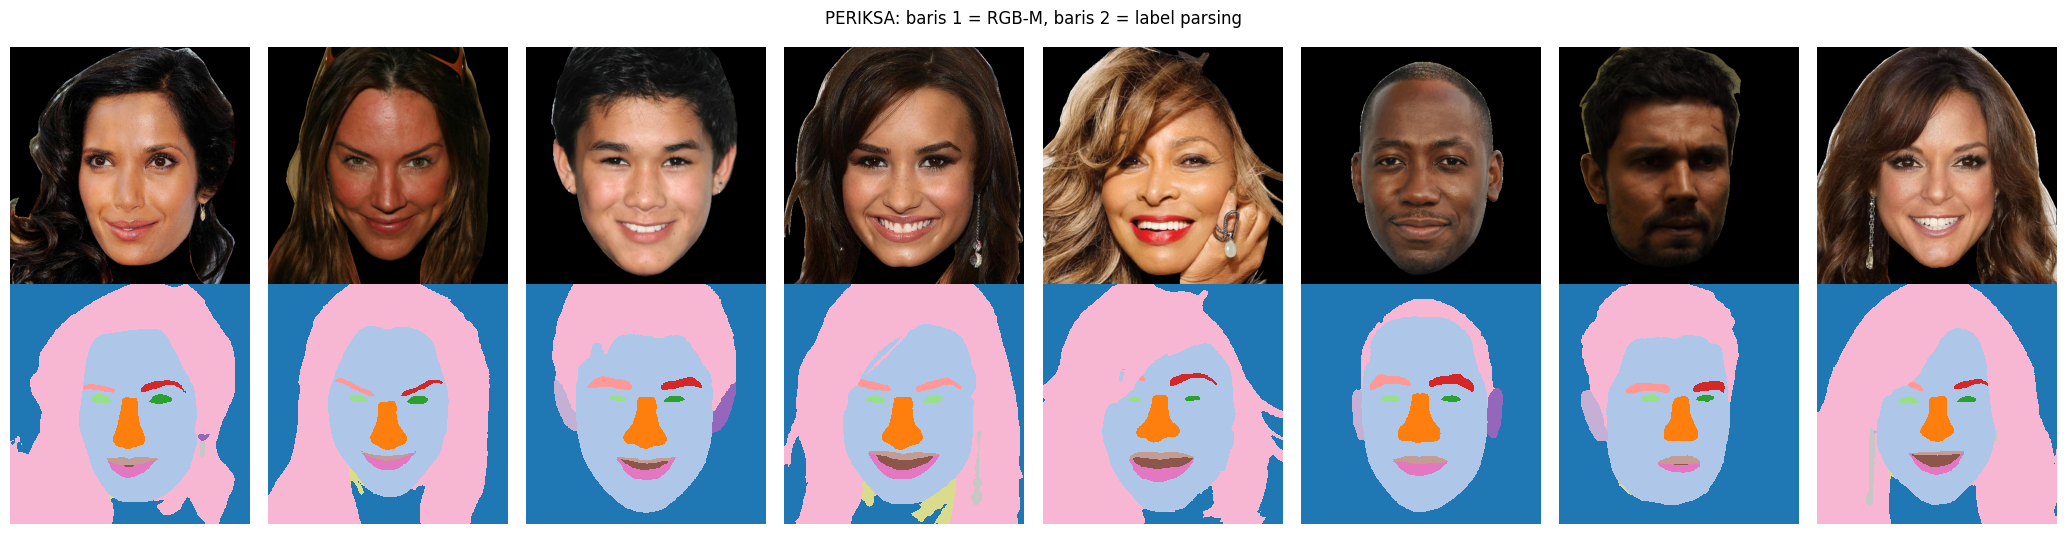

In [11]:
# ============================================================
# 3.4 PARSING SEMUA GAMBAR -> FITUR LAB + FITUR WB + CACHE GAMBAR PERSEGI
# ============================================================
REG_CACHE, IMG_CACHE_PATH = RESULT_DIR / "region_features.npz", RESULT_DIR / "img_cache.npy"
reg_meta = json.dumps({"parser": PARSER_HF_ID, "parse": PARSE_SIZE, "cache": CACHE_SIZE, "cols": REGION_COLS,
                       "wb": WB_COLS, "min": REGION_MIN_PIX, "mask": bool(MASK_OK)}, sort_keys=True)

class SquareDS(Dataset):
    def __init__(self, frame):
        self.paths = [str(p) for p in frame["resolved_path"]]
        self.masks = [str(p) for p in frame["mask_path"]] if MASK_OK else None
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        big, small, valid = load_squares(self.paths[i], self.masks[i] if self.masks else None)
        return torch.from_numpy(big), torch.from_numpy(small), torch.from_numpy(valid)

REG = WB = IMG_CACHE = None
VIS = []
if REG_CACHE.exists() and IMG_CACHE_PATH.exists() and not RECOMPUTE:
    z = np.load(REG_CACHE, allow_pickle=False)
    if np.array_equal(z["md5"], md5_all) and str(z["meta"]) == reg_meta:
        REG, WB, IMG_CACHE = z["reg"], z["wb"], np.load(IMG_CACHE_PATH)
        print("Cache parsing dipakai.")

if REG is None:
    loader = DataLoader(SquareDS(df), batch_size=PARSE_BATCH, shuffle=False, num_workers=FT_NUM_WORKERS)
    reg_list, wb_list, img_list, t0 = [], [], [], time.time()
    for big, small, valid in tqdm(loader, desc="parsing"):
        maps = parse_u8(big)
        big_np, valid_np = big.numpy(), valid.numpy()
        for j in range(len(big_np)):
            reg_list.append(region_color_features(big_np[j], maps[j], REGION_IDS, GLASSES_IDS, valid_np[j]))
            wb_list.append(wb_robust_features(big_np[j], maps[j], REGION_IDS, valid_np[j]))
            if len(VIS) < 8:
                VIS.append((big_np[j].copy(), maps[j].copy()))
        img_list.append(small.numpy())
    REG, WB, IMG_CACHE = np.stack(reg_list), np.stack(wb_list), np.concatenate(img_list)
    np.savez_compressed(REG_CACHE, reg=REG, wb=WB, md5=md5_all, meta=reg_meta)
    np.save(IMG_CACHE_PATH, IMG_CACHE)
    print(f"Parsing selesai dalam {(time.time() - t0) / 60:.1f} menit.")
assert REG.shape == (N_ALL, len(REGION_COLS)) and WB.shape == (N_ALL, len(WB_COLS))
assert IMG_CACHE.shape == (N_ALL, CACHE_SIZE, CACHE_SIZE, 3)

FEATS = {"lab": REG, "lab_wb": np.hstack([REG, WB])}
FEAT_COLS = {"lab": REGION_COLS, "lab_wb": REGION_COLS + WB_COLS}
found = {r: float(np.isfinite(REG[:, COL_IX[f"{r}_L"]]).mean()) for r in REGION_PARTS}
print("Proporsi gambar dengan region terdeteksi:", {k: round(v, 3) for k, v in found.items()})
print("Proporsi nilai fitur WB yang terisi:", round(float(np.isfinite(WB).mean()), 3))
if VIS:
    fig, axes = plt.subplots(2, len(VIS), figsize=(2.6 * len(VIS), 5.4))
    for j, (im, mp) in enumerate(VIS):
        axes[0, j].imshow(im); axes[0, j].axis("off")
        axes[1, j].imshow(mp, cmap="tab20", vmin=0, vmax=19, interpolation="nearest"); axes[1, j].axis("off")
    plt.suptitle("PERIKSA: baris 1 = RGB-M, baris 2 = label parsing")
    plt.tight_layout(); plt.show()
del parser; gc.collect()
if USE_AMP:
    torch.cuda.empty_cache()

In [12]:
# ============================================================
# 4.1 EMBEDDING FROZEN
# ============================================================
emb_meta = json.dumps({"model": FROZEN_HF_ID, "img": EMB_IMG_SIZE, "cache": CACHE_SIZE, "layers": EXTRA_MEAN_LAYERS}, sort_keys=True)
frozen = load_backbone(FROZEN_HF_ID).float().to(DEVICE).eval()
for p in frozen.parameters():
    p.requires_grad_(False)
FZ_HIDDEN = int(frozen.config.hidden_size)
FZ_PREFIX = 1 + int(getattr(frozen.config, "num_register_tokens", 0))

def u8_to_input(batch_u8_np, size):
    x = torch.from_numpy(batch_u8_np).to(DEVICE).permute(0, 3, 1, 2).float() / 255.0
    if x.shape[-1] != size:
        x = F.interpolate(x, size=(size, size), mode="bilinear", antialias=True, align_corners=False)
    return (x - _MEAN_T) / _STD_T

@torch.no_grad()
def embed_u8(batch_u8_np):
    x = u8_to_input(batch_u8_np, EMB_IMG_SIZE)
    acc = None
    for xx in (x, torch.flip(x, dims=[3])):
        out = frozen(pixel_values=xx, output_hidden_states=True)
        last, hs = out.last_hidden_state, out.hidden_states
        f = {"cls_last": last[:, 0], "mean_last": last[:, FZ_PREFIX:].mean(1)}
        for li in EXTRA_MEAN_LAYERS:
            f[f"mean_L{li}"] = hs[li][:, FZ_PREFIX:].mean(1)
        acc = f if acc is None else {k: acc[k] + f[k] for k in f}
    return {k: (v / 2).float().cpu().numpy() for k, v in acc.items()}

EMB_PATH = RESULT_DIR / "frozen_embeddings.npz"
EMB = None
if EMB_PATH.exists() and not RECOMPUTE:
    z = np.load(EMB_PATH, allow_pickle=False)
    if np.array_equal(z["md5"], md5_all) and str(z["meta"]) == emb_meta:
        EMB = {k: z[k] for k in z.files if k not in ("md5", "meta")}
        print("Cache embedding dipakai.")
if EMB is None:
    chunks = {}
    for s in tqdm(range(0, N_ALL, 64), desc="embedding"):
        for k, v in embed_u8(IMG_CACHE[s:s + 64]).items():
            chunks.setdefault(k, []).append(v)
    EMB = {k: np.concatenate(v) for k, v in chunks.items()}
    np.savez_compressed(EMB_PATH, md5=md5_all, meta=emb_meta, **EMB)
del frozen; gc.collect()
if USE_AMP:
    torch.cuda.empty_cache()
print({k: v.shape for k, v in EMB.items()})

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 86.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

embedding:   0%|          | 0/77 [00:00<?, ?it/s]

{'cls_last': (4920, 384), 'mean_last': (4920, 384), 'mean_L4': (4920, 384), 'mean_L8': (4920, 384)}


In [13]:
# ============================================================
# 5.1 NEAR-DUPLICATE
# ============================================================
E = EMB["cls_last"].astype(np.float32)
E = E - E[train_rows].mean(0, keepdims=True)
E /= np.clip(np.linalg.norm(E, axis=1, keepdims=True), 1e-8, None)
SIM = E @ E.T
np.fill_diagonal(SIM, -1.0)
iu, ju = np.triu_indices(N_ALL, k=1)
m_sel = SIM[iu, ju] >= DUP_THR
dup_pairs = np.stack([iu[m_sel], ju[m_sel]], axis=1)
n_cross = int((is_train[dup_pairs[:, 0]] != is_train[dup_pairs[:, 1]]).sum())
print(f"Near-duplicate (>= {DUP_THR}): {len(dup_pairs)} pasangan, {n_cross} menyeberang train/test resmi.")
del SIM, iu, ju, m_sel, E; gc.collect()

Near-duplicate (>= 0.9): 109 pasangan, 43 menyeberang train/test resmi.


0

In [14]:
# ============================================================
# 5.2 GRUP PER ORANG -> HOLDOUT -> FOLD CV
# ============================================================
def name_key(rel):
    # "RGB-M/train/autunno/deep/Elisabetta-Canalis 9.png" -> "elisabetta canalis"
    s = Path(str(rel).replace("\\", "/")).stem.lower()
    s = re.sub(r"[_\-.]+", " ", s)
    prev = None
    while prev != s:
        prev = s
        s = re.sub(r"\s*\(?\d+\)?\s*$", "", s).strip()
    return re.sub(r"\s+", " ", s)

is_cel_all = df["celeba"].to_numpy(dtype=bool)
stems = df[MASKED_PATH_COL].map(lambda r: Path(str(r).replace("\\", "/")).stem).to_numpy()
key_groups = {}

# (1) nama file non-CelebA
keys = df[MASKED_PATH_COL].map(name_key).to_numpy()
generic_hits = 0
for i in np.where(~is_cel_all)[0]:
    k = keys[i]
    if len(k) < 3 or k in GENERIC_NAMES or k.isdigit():
        generic_hits += 1
        continue
    key_groups.setdefault("name:" + k, []).append(int(i))
print(f"Foto non-CelebA bernama generik (tidak dikelompokkan lewat nama): {generic_hits}")

# (2) identitas asli CelebA (opsional)
IDENTITY_USED = False
if USE_CELEBA_IDENTITY:
    def find_file(name):
        hits = sorted(KAGGLE_INPUT.rglob(name))
        return hits[0] if hits else None
    f_map, f_id = find_file("CelebA-HQ-to-CelebA-mapping.txt"), find_file("identity_CelebA.txt")
    if f_map is None or f_id is None:
        print("Identitas CelebA: file pemetaan tidak ditemukan di /kaggle/input -> dilewati.")
    else:
        mp = pd.read_csv(f_map, sep=r"\s+")
        ident = pd.read_csv(f_id, sep=r"\s+", header=None, names=["orig_file", "pid"])
        hq = mp.merge(ident, on="orig_file", how="inner")
        hq2pid = dict(zip(hq["idx"].astype(int), hq["pid"].astype(int)))
        pid = np.array([hq2pid.get(int(s), -1) if (c and str(s).isdigit()) else -1 for s, c in zip(stems, is_cel_all)])
        both = [(a, b) for a, b in dup_pairs if pid[a] >= 0 and pid[b] >= 0]
        agree = float(np.mean([pid[a] == pid[b] for a, b in both])) if both else float("nan")
        print(f"Identitas CelebA: {int((pid >= 0).sum())} dari {int(is_cel_all.sum())} foto CelebA terpetakan | "
              f"kecocokan pada {len(both)} pasangan near-duplicate = {agree:.1%}")
        if len(both) >= 5 and agree >= IDENTITY_MIN_AGREEMENT:
            IDENTITY_USED = True
            for i in np.where(pid >= 0)[0]:
                key_groups.setdefault(f"pid:{pid[i]}", []).append(int(i))
            print("-> identitas CelebA DIPAKAI untuk pengelompokan.")
        else:
            print("-> kecocokan rendah (nama file dataset kemungkinan bukan indeks CelebA-HQ) -> identitas TIDAK dipakai.")

edges = [dup_pairs] if len(dup_pairs) else []
for members in key_groups.values():
    if len(members) > 1:
        edges.append(np.array([[members[0], j] for j in members[1:]]))
if edges:
    e = np.concatenate(edges)
    _, lab = connected_components(coo_matrix((np.ones(len(e)), (e[:, 0], e[:, 1])), shape=(N_ALL, N_ALL)), directed=False)
else:
    lab = np.arange(N_ALL)
groups_all = lab.astype(str)
gsize = pd.Series(groups_all).value_counts()
print(f"Grup unik: {len(gsize)} | grup terbesar: {int(gsize.iloc[0])} foto (E12: 396 karena nama 'images')")

# --- Holdout: satu lipatan StratifiedGroupKFold, hanya baris CelebA disisihkan ---
official_train_rows = train_rows.copy()
g_off = groups_all[official_train_rows]
strata_all = (df["joint_label"] + "|" + df["celeba"].astype(int).astype(str)).to_numpy()
n_sp = max(2, int(round(1.0 / HOLDOUT_FRAC)))
sp = StratifiedGroupKFold(n_splits=n_sp, shuffle=True, random_state=SEED + 1)
_, cand = next(iter(sp.split(np.zeros(len(g_off)), strata_all[official_train_rows], groups=g_off)))
ho_local = cand[is_cel_all[official_train_rows][cand]]
hold_groups = set(g_off[ho_local])
keep_local = np.array([i for i in range(len(g_off)) if g_off[i] not in hold_groups])
hold_rows, train_rows = official_train_rows[ho_local], official_train_rows[keep_local]
n_dropped = len(official_train_rows) - len(hold_rows) - len(train_rows)
assert len(set(groups_all[hold_rows]) & set(groups_all[train_rows])) == 0, "Grup bocor antara holdout dan train."

y12 = ALL_Y["y12"][train_rows]
yho = ALL_Y["y12"][hold_rows]
cel = is_cel_all[train_rows]
groups_tr = groups_all[train_rows]
strata = strata_all[train_rows]
print(f"Official train {len(official_train_rows)} -> pengembangan {len(train_rows)} (CelebA {int(cel.sum())}) + holdout {len(hold_rows)}"
      + (f" (+{n_dropped} non-CelebA dibuang karena segrup dengan holdout)" if n_dropped else ""))

splitter = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(splitter.split(np.zeros(len(strata)), strata, groups=groups_tr))
fold_id = np.zeros(len(strata), dtype=int)
for k, (_, va) in enumerate(folds):
    fold_id[va] = k
assert all(len(set(groups_tr[tr]) & set(groups_tr[va])) == 0 for tr, va in folds), "Grup bocor antar fold."
FOLD_HASH = hashlib.md5(fold_id.tobytes() + train_rows.astype(np.int64).tobytes()).hexdigest()[:10]
display(pd.DataFrame({"n": np.bincount(fold_id), "n_celeba": np.bincount(fold_id, weights=cel).astype(int)}).T)

Foto non-CelebA bernama generik (tidak dikelompokkan lewat nama): 397
Identitas CelebA: file pemetaan tidak ditemukan di /kaggle/input -> dilewati.
Grup unik: 3665 | grup terbesar: 59 foto (E12: 396 karena nama 'images')
Official train 4008 -> pengembangan 3594 (CelebA 1655) + holdout 414


,0,1,2,3,4
n,750,620,689,749,786
n_celeba,320,333,361,328,313


In [15]:
# ============================================================
# 6.1 METRIK DAN HELPER
# ============================================================
def ece_score(correct, conf, n_bins=ECE_BINS):
    edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        m = (conf >= edges[i]) & ((conf < edges[i + 1]) if i < n_bins - 1 else (conf <= edges[i + 1]))
        if m.any():
            ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(ece)

def topk_hit(y, probs, k):
    idx = np.argsort(-probs, axis=1)[:, :k]
    return float((idx == y[:, None]).any(1).mean())

def full_metrics(y, probs):
    pred, conf = probs.argmax(1), probs.max(1)
    correct = pred == y
    _, rec, f1c, _ = precision_recall_fscore_support(y, pred, labels=list(range(NUM_CLASSES)), zero_division=0)
    tp = np.clip(probs[np.arange(len(y)), y], 1e-12, 1.0)
    return {
        "acc": float(correct.mean()),
        "macro_f1": float(f1c.mean()),
        "top2": topk_hit(y, probs, 2),
        "top3": topk_hit(y, probs, 3),
        "worst3_recall": float(np.sort(rec)[:3].mean()),
        "nll": float(-np.log(tp).mean()),
        "ece": ece_score(correct, conf),
    }

def nll_of(p, y):
    return float(-np.log(np.clip(p[np.arange(len(y)), y], 1e-12, 1)).mean())

def apply_temperature(p, T):
    z = np.log(np.clip(p, 1e-12, 1.0)) / float(T)
    z -= z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def fit_temperature(y, p, lo=0.05, hi=10.0):
    return float(minimize_scalar(lambda T: nll_of(apply_temperature(p, T), y), bounds=(lo, hi), method="bounded").x)

def pool(prob_list, weights):
    z = sum(w * np.log(np.clip(p, 1e-12, 1.0)) for p, w in zip(prob_list, weights))
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def proba_full(model, X):
    p = model.predict_proba(X)
    out = np.zeros((len(X), NUM_CLASSES))
    out[:, model.classes_] = p
    return out

SHOW = ["acc", "macro_f1", "top2", "top3", "worst3_recall", "nll", "ece"]
COMP_OOF, COMP_TEST, COMP_HOLD, COMP_MODEL = {}, {}, {}, {}
print("Helper siap.")

Helper siap.


In [16]:
# ============================================================
# 5.3 DIAGNOSTIK: APAKAH FITUR WB MEMBANTU MEMBEDAKAN PASANGAN YANG SERING TERTUKAR?
# ============================================================
# AUROC biner out-of-fold per pasangan sub-season, hanya data pengembangan (official test & holdout tidak dipakai).
from sklearn.metrics import roc_auc_score

def fill_nan(X, rows_fit):
    med = np.nanmedian(X[rows_fit], axis=0)
    med = np.where(np.isfinite(med), med, 0.0)
    return np.hstack([np.where(np.isfinite(X), X, med), (~np.isfinite(X)).astype(np.float64)])

def pair_auc(X, a, b, C=0.1):
    scores, ys = [], []
    for tr, va in folds:
        trm, vam = tr[np.isin(y12[tr], [a, b])], va[np.isin(y12[va], [a, b])]
        if len(vam) == 0 or len(np.unique(y12[trm])) < 2:
            continue
        m = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000)).fit(X[train_rows[trm]], (y12[trm] == b).astype(int))
        scores.append(m.predict_proba(X[train_rows[vam]])[:, 1]); ys.append((y12[vam] == b).astype(int))
    yy = np.concatenate(ys)
    return float(roc_auc_score(yy, np.concatenate(scores))) if len(np.unique(yy)) == 2 else np.nan

X_FILLED = {k: fill_nan(v, train_rows) for k, v in FEATS.items()}
X_FILLED["wb_only"] = fill_nan(WB, train_rows)
rows = []
for a, b in FOCUS_PAIRS:
    ia, ib = class2idx[a], class2idx[b]
    rows.append({"pasangan": f"{a} vs {b}", **{f"auroc_{k}": pair_auc(X_FILLED[k], ia, ib) for k in ["lab", "wb_only", "lab_wb"]}})
diag_df = pd.DataFrame(rows)
diag_df["selisih_lab_wb_vs_lab"] = diag_df["auroc_lab_wb"] - diag_df["auroc_lab"]
display(diag_df.round(3))
diag_df.to_csv(RESULT_DIR / "E15_pair_auroc.csv", index=False)
print("AUROC 0,5 = tidak bisa dibedakan. Kolom selisih > 0 berarti fitur WB menambah daya pembeda untuk pasangan itu.")

,pasangan,auroc_lab,auroc_wb_only,auroc_lab_wb,selisih_lab_wb_vs_lab
0,autunno_deep vs inverno_deep,0.668,0.661,0.662,-0.006
1,estate_light vs primavera_light,0.634,0.642,0.647,0.013
2,inverno_cool vs inverno_deep,0.765,0.774,0.776,0.011
3,autunno_warm vs primavera_warm,0.805,0.792,0.810,0.005
4,estate_soft vs autunno_soft,0.797,0.737,0.799,0.002
5,primavera_bright vs inverno_bright,0.759,0.774,0.770,0.012


AUROC 0,5 = tidak bisa dibedakan. Kolom selisih > 0 berarti fitur WB menambah daya pembeda untuk pasangan itu.


## 6. Komponen klasik — masing-masing untuk set fitur `lab` dan `lab_wb`

- `emb_lr`: embedding frozen saja (tidak bergantung set fitur, dipakai di kedua ensemble).
- `color_hgb[...]`: HistGradientBoosting di atas fitur warna; kurva loss train/validasi per fold.
- `emb_color_lr[...]`: logistic regression di atas embedding frozen + fitur warna; tabel loss per C.

In [17]:
# ============================================================
# 6.2 KOMPONEN emb_lr (loss = log-loss OOF per C)
# ============================================================
EMB_KEYS = ["cls_last", "mean_last"] + [f"mean_L{l}" for l in EXTRA_MEAN_LAYERS]
X_emb = np.hstack([EMB[k] for k in EMB_KEYS]).astype(np.float64)

def make_lr(C):
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000))

rows, lr_oofs = [], {}
for C in C_GRID:
    t0 = time.time()
    oof = np.zeros((len(train_rows), NUM_CLASSES))
    fold_loss = []
    for tr, va in folds:
        m = make_lr(C).fit(X_emb[train_rows[tr]], y12[tr])
        oof[va] = proba_full(m, X_emb[train_rows[va]])
        fold_loss.append((nll_of(proba_full(m, X_emb[train_rows[tr]]), y12[tr]), nll_of(oof[va], y12[va])))
    lr_oofs[C] = oof
    rows.append({"C": C, "train_loss": np.mean([a for a, _ in fold_loss]), "val_loss": np.mean([b for _, b in fold_loss]),
                 "val_loss_celeba": nll_of(oof[cel], y12[cel]), "acc_celeba": float((oof[cel].argmax(1) == y12[cel]).mean()),
                 "sec": round(time.time() - t0, 1)})
lr_df = pd.DataFrame(rows)
display(lr_df.round(4))
BEST_C = float(lr_df.sort_values("val_loss_celeba").iloc[0]["C"])
print("C terpilih:", BEST_C)
COMP_OOF["emb_lr"] = lr_oofs[BEST_C]
COMP_MODEL["emb_lr"] = make_lr(BEST_C).fit(X_emb[train_rows], y12)
COMP_TEST["emb_lr"] = proba_full(COMP_MODEL["emb_lr"], X_emb[test_rows])
COMP_HOLD["emb_lr"] = proba_full(COMP_MODEL["emb_lr"], X_emb[hold_rows])

,C,train_loss,val_loss,val_loss_celeba,acc_celeba,sec
0,0.0003,1.7290,1.9833,2.0024,0.2634,32.2
1,0.0010,1.4755,1.9097,1.9670,0.2767,51.6
2,0.0030,1.2105,1.9094,2.0069,0.2792,74.6


C terpilih: 0.001


color_hgb[lab] fold 0: iter=143 train_loss=0.5157 val_loss(internal)=1.7723 val_loss(fold)=2.0503
color_hgb[lab] fold 1: iter=158 train_loss=0.4756 val_loss(internal)=1.8044 val_loss(fold)=1.9552
color_hgb[lab] fold 2: iter=161 train_loss=0.4418 val_loss(internal)=1.7705 val_loss(fold)=1.9564
color_hgb[lab] fold 3: iter=141 train_loss=0.5099 val_loss(internal)=1.7359 val_loss(fold)=1.9575
color_hgb[lab] fold 4: iter=145 train_loss=0.5244 val_loss(internal)=1.7634 val_loss(fold)=1.8739


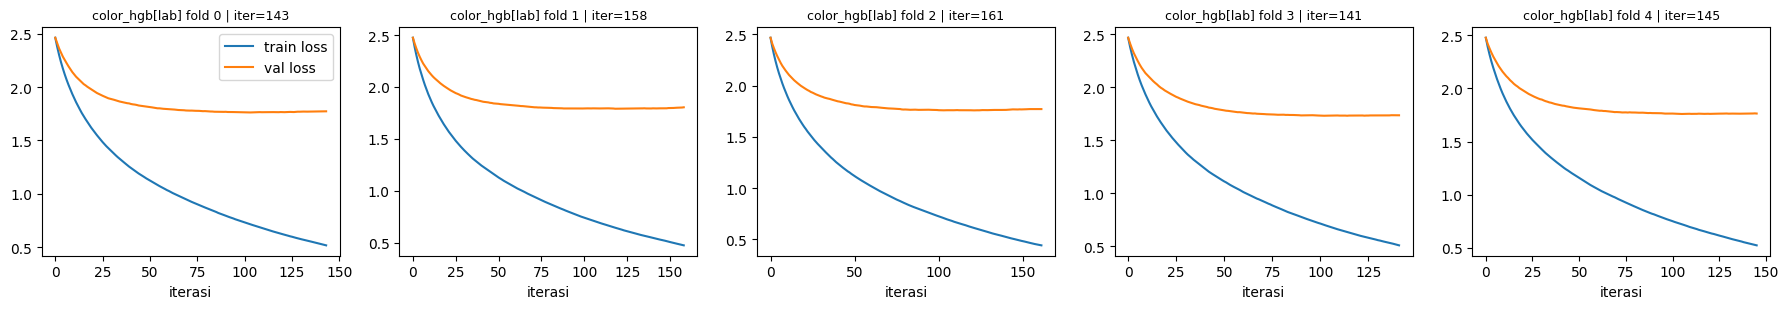

color_hgb[lab_wb] fold 0: iter=173 train_loss=0.3396 val_loss(internal)=1.7310 val_loss(fold)=2.0272
color_hgb[lab_wb] fold 1: iter=141 train_loss=0.4474 val_loss(internal)=1.7382 val_loss(fold)=1.8958
color_hgb[lab_wb] fold 2: iter=180 train_loss=0.3032 val_loss(internal)=1.7152 val_loss(fold)=1.9025
color_hgb[lab_wb] fold 3: iter=169 train_loss=0.3369 val_loss(internal)=1.6976 val_loss(fold)=1.9756
color_hgb[lab_wb] fold 4: iter=149 train_loss=0.4285 val_loss(internal)=1.7220 val_loss(fold)=1.8730


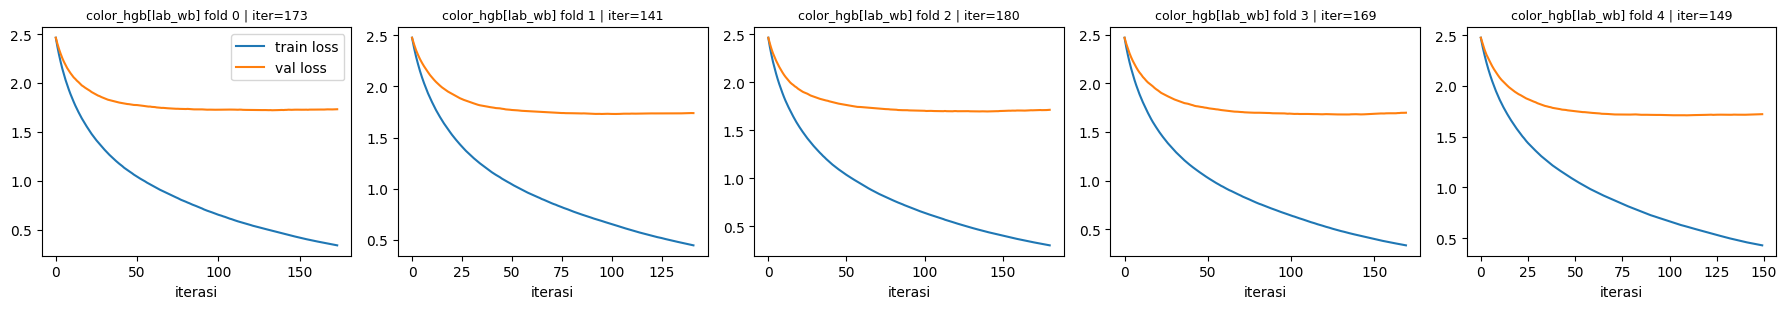

In [18]:
# ============================================================
# 6.3 KOMPONEN color_hgb PER SET FITUR (kurva loss train/validasi per fold)
# ============================================================
def make_hgb():
    return HistGradientBoostingClassifier(learning_rate=0.04, max_iter=600, max_depth=4, l2_regularization=1.0,
                                          max_leaf_nodes=15, min_samples_leaf=25, early_stopping=True,
                                          scoring="loss", validation_fraction=0.15, n_iter_no_change=40,
                                          random_state=SEED)

for fs in FEATURE_SETS:
    X = FEATS[fs]
    keep = np.where(np.isfinite(X[train_rows]).mean(0) >= 0.02)[0]
    X = X[:, keep].astype(np.float64)
    name = f"color_hgb[{fs}]"
    oof = np.zeros((len(train_rows), NUM_CLASSES))
    fig, axes = plt.subplots(1, len(folds), figsize=(3.6 * len(folds), 3.2), squeeze=False)
    for k, (tr, va) in enumerate(folds):
        m = make_hgb().fit(X[train_rows[tr]], y12[tr])
        oof[va] = proba_full(m, X[train_rows[va]])
        ax = axes[0, k]
        ax.plot(-m.train_score_, label="train loss"); ax.plot(-m.validation_score_, label="val loss")
        ax.set_title(f"{name} fold {k} | iter={m.n_iter_}", fontsize=9); ax.set_xlabel("iterasi")
        print(f"{name} fold {k}: iter={m.n_iter_} train_loss={-m.train_score_[-1]:.4f} "
              f"val_loss(internal)={-m.validation_score_[-1]:.4f} val_loss(fold)={nll_of(oof[va], y12[va]):.4f}")
    axes[0, 0].legend(); plt.tight_layout(); plt.show()
    COMP_OOF[name] = oof
    COMP_MODEL[name] = make_hgb().fit(X[train_rows], y12)
    COMP_TEST[name] = proba_full(COMP_MODEL[name], X[test_rows])
    COMP_HOLD[name] = proba_full(COMP_MODEL[name], X[hold_rows])

In [19]:
# ============================================================
# 6.4 KOMPONEN emb_color_lr PER SET FITUR (loss = log-loss OOF per C)
# ============================================================
BEST_C_EC = {}
for fs in FEATURE_SETS:
    X_ec = np.hstack([X_emb, X_FILLED[fs]])
    name = f"emb_color_lr[{fs}]"
    rows, ec_oofs = [], {}
    for C in C_GRID:
        t0 = time.time()
        oof = np.zeros((len(train_rows), NUM_CLASSES))
        fold_loss = []
        for tr, va in folds:
            m = make_lr(C).fit(X_ec[train_rows[tr]], y12[tr])
            oof[va] = proba_full(m, X_ec[train_rows[va]])
            fold_loss.append((nll_of(proba_full(m, X_ec[train_rows[tr]]), y12[tr]), nll_of(oof[va], y12[va])))
        ec_oofs[C] = oof
        rows.append({"komponen": name, "C": C, "train_loss": np.mean([a for a, _ in fold_loss]),
                     "val_loss": np.mean([b for _, b in fold_loss]), "val_loss_celeba": nll_of(oof[cel], y12[cel]),
                     "acc_celeba": float((oof[cel].argmax(1) == y12[cel]).mean()), "sec": round(time.time() - t0, 1)})
    ec_df = pd.DataFrame(rows)
    display(ec_df.round(4))
    BEST_C_EC[fs] = float(ec_df.sort_values("val_loss_celeba").iloc[0]["C"])
    COMP_OOF[name] = ec_oofs[BEST_C_EC[fs]]
    COMP_MODEL[name] = make_lr(BEST_C_EC[fs]).fit(X_ec[train_rows], y12)
    COMP_TEST[name] = proba_full(COMP_MODEL[name], X_ec[test_rows])
    COMP_HOLD[name] = proba_full(COMP_MODEL[name], X_ec[hold_rows])
print("C terpilih emb_color_lr:", BEST_C_EC)

def comp_table(comp, y, mask=None):
    return pd.DataFrame({k: full_metrics(y if mask is None else y[mask], v if mask is None else v[mask]) for k, v in comp.items()}).T[SHOW]

print("OOF subset CelebA:")
display(comp_table(COMP_OOF, y12, cel).round(4))

,komponen,C,train_loss,val_loss,val_loss_celeba,acc_celeba,sec
0,emb_color_lr[lab],0.0003,1.6552,1.9246,1.9561,0.2888,34.2
1,emb_color_lr[lab],0.0010,1.3829,1.8362,1.9215,0.3015,58.5
2,emb_color_lr[lab],0.0030,1.1059,1.8211,1.9637,0.3027,81.3


,komponen,C,train_loss,val_loss,val_loss_celeba,acc_celeba,sec
0,emb_color_lr[lab_wb],0.0003,1.6082,1.8840,1.9292,0.2991,45.9
1,emb_color_lr[lab_wb],0.0010,1.3380,1.7984,1.9043,0.3106,65.5
2,emb_color_lr[lab_wb],0.0030,1.0683,1.7934,1.9596,0.3112,86.3


C terpilih emb_color_lr: {'lab': 0.001, 'lab_wb': 0.001}
OOF subset CelebA:


,acc,macro_f1,top2,top3,worst3_recall,nll,ece
emb_lr,0.2767,0.2519,0.4888,0.6211,0.1222,1.9670,0.0508
color_hgb[lab],0.2991,0.2857,0.4943,0.6218,0.1714,2.0381,0.1284
color_hgb[lab_wb],0.3057,0.2892,0.5088,0.6332,0.1807,2.0466,0.1502
emb_color_lr[lab],0.3015,0.2802,0.5082,0.6514,0.1649,1.9215,0.0461
emb_color_lr[lab_wb],0.3106,0.2902,0.5142,0.6568,0.1712,1.9043,0.0485


## 7. Fine-tuning fusion DINOv3 ViT-S — sekali dengan `lab`, sekali dengan `lab_wb`

Arsitektur dan regularisasi sama dengan E14 (cabang gambar DINOv3 + cabang MLP fitur warna, logit hierarkis, label smoothing hierarkis, EMA, 4 blok awal dibekukan, stochastic depth). Satu-satunya perbedaan antar dua run adalah **isi cabang warna**: 87 fitur Lab, atau 87 + 70 fitur tahan white balance. Seed dan fold identik.

Tiap epoch mencetak **train loss** (total dan CE 12 kelas) serta **val loss**, val acc, dan val acc CelebA; di akhir tiap run dicetak loss dan akurasi **snapshot** (epoch 4–8).

In [20]:
# ============================================================
# 7.1 DATASET, MODEL, LOSS, LOOP TRAINING
# ============================================================
train_tf = transforms.Compose([
    transforms.RandomRotation(8),
    transforms.RandomResizedCrop(FT_IMG_SIZE, scale=(0.6, 1.0), ratio=(0.9, 1.1), antialias=True),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(IMNET_MEAN, IMNET_STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((FT_IMG_SIZE, FT_IMG_SIZE), antialias=True),
    transforms.ToTensor(),
    transforms.Normalize(IMNET_MEAN, IMNET_STD),
])

class ColorPrep:
    # Isi NaN dengan median train, standarkan, tambah indikator hilang. Di-fit per fold (hanya baris train fold).
    def fit(self, X):
        self.keep = np.where(np.isfinite(X).mean(0) >= 0.02)[0]
        Xk = X[:, self.keep]
        self.med = np.nanmedian(Xk, axis=0)
        self.miss = np.where(~np.isfinite(Xk).all(0))[0]
        Z = np.where(np.isfinite(Xk), Xk, self.med)
        self.mu, self.sd = Z.mean(0), Z.std(0) + 1e-6
        return self
    def transform(self, X):
        Xk = X[:, self.keep]
        Z = np.clip((np.where(np.isfinite(Xk), Xk, self.med) - self.mu) / self.sd, -5, 5)
        M = (~np.isfinite(Xk[:, self.miss])).astype(np.float64)
        return np.hstack([Z, M]).astype(np.float32)
    @property
    def dim(self):
        return len(self.keep) + len(self.miss)

class FTDataset(Dataset):
    def __init__(self, rows, train, colorZ):
        self.rows, self.tf, self.colorZ = np.asarray(rows), (train_tf if train else eval_tf), colorZ
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, i):
        r = int(self.rows[i])
        x = self.tf(Image.fromarray(IMG_CACHE[r]))
        return (x, torch.from_numpy(self.colorZ[r]), int(ALL_Y["y12"][r]), int(ALL_Y["yS"][r]),
                int(ALL_Y["yC"][r]), int(ALL_Y["yU"][r]))

class FusionNet(nn.Module):
    def __init__(self, backbone, color_dim):
        super().__init__()
        self.backbone = backbone
        d = int(backbone.config.hidden_size)
        self.n_prefix = 1 + int(getattr(backbone.config, "num_register_tokens", 0))
        self.use_color = FT_USE_COLOR and color_dim > 0
        feat = 2 * d
        if self.use_color:
            self.color_mlp = nn.Sequential(nn.Linear(color_dim, FT_COLOR_HIDDEN), nn.GELU(), nn.Dropout(FT_DROPOUT),
                                           nn.Linear(FT_COLOR_HIDDEN, FT_COLOR_HIDDEN), nn.GELU())
            feat += FT_COLOR_HIDDEN
        self.norm = nn.LayerNorm(feat)
        self.drop = nn.Dropout(FT_DROPOUT)
        self.head12 = nn.Linear(feat, NUM_CLASSES)
        self.headS = nn.Linear(feat, NUM_SEASONS)
        self.headC = nn.Linear(feat, NUM_CHARS)
        self.headU = nn.Linear(feat, 2)
        self.register_buffer("season_of", torch.as_tensor(season_of, dtype=torch.long))
        self.register_buffer("char_of", torch.as_tensor(char_of, dtype=torch.long))
        self.register_buffer("warm_of", torch.as_tensor(warm_of, dtype=torch.long))

    def forward(self, x, c):
        h = self.backbone(pixel_values=x).last_hidden_state
        f = torch.cat([h[:, 0], h[:, self.n_prefix:].mean(1)], dim=1)
        if self.use_color:
            if self.training and FT_COLOR_DROP > 0:
                c = c * (torch.rand(c.shape[0], 1, device=c.device) >= FT_COLOR_DROP).to(c.dtype)
            f = torch.cat([f, self.color_mlp(c)], dim=1)
        f = self.drop(self.norm(f))
        z12, zS, zC, zU = self.head12(f), self.headS(f), self.headC(f), self.headU(f)
        if FT_HIER_LOGITS:
            z12 = z12 + zS[:, self.season_of] + zC[:, self.char_of] + zU[:, self.warm_of]
        return z12, zS, zC, zU

def build_soft_targets():
    if not FT_HIER_SMOOTH:
        W = np.ones((NUM_CLASSES, NUM_CLASSES))
    else:
        W = (1.0 + (season_of[:, None] == season_of[None, :]) * 1.0
             + (char_of[:, None] == char_of[None, :]) * 1.0
             + (warm_of[:, None] == warm_of[None, :]) * 0.5)
    np.fill_diagonal(W, 0.0)
    W = W / W.sum(1, keepdims=True)
    return torch.tensor((1 - FT_LABEL_SMOOTH) * np.eye(NUM_CLASSES) + FT_LABEL_SMOOTH * W, dtype=torch.float32)

SOFT_T = build_soft_targets().to(DEVICE)

def loss_fn(outs, a, b, c, d):
    o12, oS, oC, oU = (o.float() for o in outs)
    ce12 = -(SOFT_T[a] * F.log_softmax(o12, dim=1)).sum(1).mean()
    aux = F.cross_entropy(oS, b) + F.cross_entropy(oC, c) + F.cross_entropy(oU, d)
    return ce12 + FT_AUX_W * aux, ce12

def build_optimizer(model):
    n_layers = int(model.backbone.config.num_hidden_layers)
    groups, matched = {}, 0
    for name, p in model.backbone.named_parameters():
        if not p.requires_grad:
            continue
        m = re.search(r"(?:^|\.)layers?\.(\d+)\.", name)
        if m:
            depth, matched = int(m.group(1)) + 1, matched + 1
        elif "embed" in name:
            depth = 0
        else:
            depth = n_layers
        lr = FT_LR_BACKBONE * (FT_LLRD ** (n_layers - depth))
        groups.setdefault((lr, 0.0 if p.ndim <= 1 else FT_WD), []).append(p)
    if matched == 0:
        print("PERINGATAN: nama layer tidak dikenali; semua layer backbone memakai LR yang sama.")
    for name, p in model.named_parameters():
        if not name.startswith("backbone."):
            groups.setdefault((FT_LR_HEAD, 0.0 if p.ndim <= 1 else FT_WD), []).append(p)
    return torch.optim.AdamW([{"params": ps, "lr": lr, "weight_decay": wd} for (lr, wd), ps in groups.items()])

def make_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except Exception:
        return torch.cuda.amp.GradScaler(enabled=USE_AMP)

@torch.no_grad()
def ema_update(ema_m, m, decay):
    msd = m.state_dict()
    for k, v in ema_m.state_dict().items():
        if v.dtype.is_floating_point:
            v.mul_(decay).add_(msd[k].detach(), alpha=1 - decay)
        else:
            v.copy_(msd[k])

@torch.no_grad()
def predict_rows(model, rows, colorZ, tta=True):
    model.eval()
    loader = DataLoader(FTDataset(rows, False, colorZ), batch_size=128, shuffle=False, num_workers=FT_NUM_WORKERS)
    outs = []
    for batch in loader:
        x, c = batch[0].to(DEVICE, non_blocking=True), batch[1].to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            p = model(x, c)[0].float().softmax(1)
            if tta:
                p = (p + model(torch.flip(x, dims=[3]), c)[0].float().softmax(1)) / 2
        outs.append(p.cpu().numpy().astype(np.float64))
    return np.concatenate(outs) if outs else np.zeros((0, NUM_CLASSES))

def freeze_lower(backbone, n_blocks):
    # bekukan patch embedding (+ token CLS/register) dan n_blocks blok transformer pertama
    n_frozen = 0
    for name, p in backbone.named_parameters():
        m = re.search(r"(?:^|\.)layers?\.(\d+)\.", name)
        if "embed" in name or (m and int(m.group(1)) < n_blocks):
            p.requires_grad_(False)
            n_frozen += p.numel()
    return n_frozen

def train_one(hf_id, tr_rows, va_rows, colorZ, color_dim, seed, tag, extra_sets):
    # extra_sets: {"te": rows, "ho": rows}. Mengembalikan model akhir (EMA), riwayat per epoch,
    # dan prediksi snapshot (rata-rata epoch FT_SNAPSHOT_FROM..FT_EPOCHS) untuk va + extra_sets.
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    try:
        bb = load_backbone(hf_id, drop_path_rate=FT_DROP_PATH)
    except Exception:
        print("  (drop_path_rate tidak didukung config ini -> tanpa stochastic depth)")
        bb = load_backbone(hf_id)
    model = FusionNet(bb.float(), color_dim).to(DEVICE)
    n_frozen = freeze_lower(model.backbone, FT_FREEZE_BLOCKS)
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"  [{tag}] parameter dibekukan {n_frozen / 1e6:.1f}M | dilatih {n_train / 1e6:.1f}M")
    ema = copy.deepcopy(model).eval() if FT_EMA > 0 else None
    if ema is not None:
        for p in ema.parameters():
            p.requires_grad_(False)
    opt = build_optimizer(model)
    loader = DataLoader(FTDataset(tr_rows, True, colorZ), batch_size=FT_BATCH, shuffle=True, drop_last=True,
                        num_workers=FT_NUM_WORKERS, pin_memory=USE_AMP, persistent_workers=FT_NUM_WORKERS > 0)
    total, warm = FT_EPOCHS * len(loader), max(1, FT_WARMUP_EPOCHS * len(loader))
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
    scaler, hist, step = make_scaler(), [], 0
    va_y, va_cel = ALL_Y["y12"][va_rows], is_cel_all[va_rows]
    snap = {"va": np.zeros((len(va_rows), NUM_CLASSES)), **{k: np.zeros((len(r), NUM_CLASSES)) for k, r in extra_sets.items()}}
    n_snap = 0
    trainable = [p for p in model.parameters() if p.requires_grad]
    for ep in range(FT_EPOCHS):
        model.train()
        run, run12, n = 0.0, 0.0, 0
        for x, cz, a, b, c, d in loader:
            x, cz = x.to(DEVICE, non_blocking=True), cz.to(DEVICE, non_blocking=True)
            a, b, c, d = a.to(DEVICE), b.to(DEVICE), c.to(DEVICE), d.to(DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                outs = model(x, cz)
            loss, ce12 = loss_fn(outs, a, b, c, d)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(trainable, 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            step += 1
            if ema is not None:
                ema_update(ema, model, min(FT_EMA, (1 + step) / (10 + step)))
            run, run12, n = run + float(loss.detach()) * len(x), run12 + float(ce12.detach()) * len(x), n + len(x)
        ev = ema if ema is not None else model
        pv = predict_rows(ev, va_rows, colorZ, tta=True)
        if ep + 1 >= FT_SNAPSHOT_FROM:
            snap["va"] += pv
            for k, r in extra_sets.items():
                snap[k] += predict_rows(ev, r, colorZ, tta=True)
            n_snap += 1
        ok = pv.argmax(1) == va_y
        hist.append({"tag": tag, "epoch": ep + 1, "train_loss": run / max(n, 1), "train_ce12": run12 / max(n, 1),
                     "val_loss": nll_of(pv, va_y), "val_acc": float(ok.mean()),
                     "val_acc_celeba": float(ok[va_cel].mean()) if va_cel.any() else float("nan")})
        hh = hist[-1]
        print(f"  [{tag}] epoch {ep + 1:2d}/{FT_EPOCHS} train_loss={hh['train_loss']:.4f} train_ce12={hh['train_ce12']:.4f} "
              f"val_loss={hh['val_loss']:.4f} val_acc={hh['val_acc']:.4f} val_acc_celeba={hh['val_acc_celeba']:.4f}"
              + ("  [snapshot]" if ep + 1 >= FT_SNAPSHOT_FROM else ""))
    snap = {k: v / max(n_snap, 1) for k, v in snap.items()}
    final = ema if ema is not None else model
    del opt, model
    return final, hist, snap

print("Fungsi fine-tuning siap. Soft target (baris 0):", np.round(SOFT_T[0].cpu().numpy(), 3))

Fungsi fine-tuning siap. Soft target (baris 0): [0.9   0.015 0.015 0.006 0.006 0.006 0.006 0.006 0.012 0.009 0.009 0.009]


In [21]:
# ============================================================
# 7.2 FINE-TUNING: SET FITUR x SEED x FOLD (cache per run: aman dilanjutkan bila sesi terputus)
# ============================================================
FT_HIST, COLOR_PREPS = [], {}
t_start = time.time()
for fs in FEATURE_SETS:
    comp = f"ft_vits[{fs}]"
    preps = {k: ColorPrep().fit(FEATS[fs][train_rows[tr]]) for k, (tr, va) in enumerate(folds)}
    COLOR_PREPS[fs] = preps
    ft_meta = json.dumps({"model": FT_HF_ID, "feat": fs, "ncol": len(FEAT_COLS[fs]), "img": FT_IMG_SIZE, "ep": FT_EPOCHS,
                          "bs": FT_BATCH, "lr": [FT_LR_HEAD, FT_LR_BACKBONE, FT_LLRD], "wd": FT_WD, "ls": FT_LABEL_SMOOTH,
                          "hs": FT_HIER_SMOOTH, "hl": FT_HIER_LOGITS, "color": [FT_USE_COLOR, FT_COLOR_HIDDEN, FT_COLOR_DROP],
                          "drop": FT_DROPOUT, "aux": FT_AUX_W, "ema": FT_EMA, "freeze": FT_FREEZE_BLOCKS,
                          "dp": FT_DROP_PATH, "snap": FT_SNAPSHOT_FROM, "folds": FOLD_HASH, "n": N_ALL,
                          "hold": int(len(hold_rows))}, sort_keys=True)
    oof_sum = np.zeros((len(train_rows), NUM_CLASSES))
    test_sum, hold_sum, n_models = np.zeros((len(test_rows), NUM_CLASSES)), np.zeros((len(hold_rows), NUM_CLASSES)), 0
    print(f"\n========== {comp} ({len(FEAT_COLS[fs])} fitur warna) ==========")
    for seed in FT_SEEDS:
        for k, (tr, va) in enumerate(folds):
            colorZ = preps[k].transform(FEATS[fs])
            tag = f"ft_vits_{fs}_s{seed}f{k}"
            cache, ckpt = RESULT_DIR / f"{tag}.npz", RESULT_DIR / f"{tag}.pt"
            if cache.exists() and not RECOMPUTE and (ckpt.exists() or not FT_SAVE_CKPT):
                z = np.load(cache, allow_pickle=False)
                if str(z["meta"]) == ft_meta and np.array_equal(z["va"], va):
                    oof_sum[va] += z["p_va"]; test_sum += z["p_te"]; hold_sum += z["p_ho"]; n_models += 1
                    FT_HIST += [{**h, "comp": comp, "seed": seed, "fold": k} for h in json.loads(str(z["hist"]))]
                    print(f"{tag}: cache dipakai.")
                    continue
            t0 = time.time()
            model, hist, snap = train_one(FT_HF_ID, train_rows[tr], train_rows[va], colorZ, preps[k].dim,
                                          seed * 100 + k, tag, {"te": test_rows, "ho": hold_rows})
            p_va, p_te, p_ho = snap["va"], snap["te"], snap["ho"]
            np.savez_compressed(cache, va=va, p_va=p_va, p_te=p_te, p_ho=p_ho, meta=ft_meta, hist=json.dumps(hist))
            if FT_SAVE_CKPT:
                torch.save({n: (v.half() if v.is_floating_point() else v) for n, v in model.state_dict().items()}, ckpt)
            oof_sum[va] += p_va; test_sum += p_te; hold_sum += p_ho; n_models += 1
            FT_HIST += [{**h, "comp": comp, "seed": seed, "fold": k} for h in hist]
            cv = cel[va]
            print(f"{tag}: selesai {(time.time() - t0) / 60:.1f} menit | SNAPSHOT val_loss = {nll_of(p_va, y12[va]):.4f} | "
                  f"val_acc = {(p_va.argmax(1) == y12[va]).mean():.4f} | "
                  f"val_acc_celeba = {(p_va[cv].argmax(1) == y12[va][cv]).mean():.4f}")
            del model; gc.collect()
            if USE_AMP:
                torch.cuda.empty_cache()
    COMP_OOF[comp] = oof_sum / len(FT_SEEDS)
    COMP_TEST[comp] = test_sum / n_models
    COMP_HOLD[comp] = hold_sum / n_models
    m = full_metrics(y12[cel], COMP_OOF[comp][cel])
    print(f"{comp}: OOF CelebA acc={m['acc']:.4f} nll={m['nll']:.4f} ece={m['ece']:.4f}")
print(f"\nFine-tuning total {(time.time() - t_start) / 60:.1f} menit.")


========== ft_vits[lab] (87 fitur warna) ==========


Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

  [ft_vits_lab_s42f0] parameter dibekukan 7.4M | dilatih 14.3M


/tmp/ipykernel_23/1825485777.py:203: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


  [ft_vits_lab_s42f0] epoch  1/8 train_loss=3.5953 train_ce12=2.5001 val_loss=2.0323 val_acc=0.2853 val_acc_celeba=0.3000
  [ft_vits_lab_s42f0] epoch  2/8 train_loss=3.1867 train_ce12=2.2523 val_loss=2.0410 val_acc=0.3027 val_acc_celeba=0.2750
  [ft_vits_lab_s42f0] epoch  3/8 train_loss=3.0598 train_ce12=2.1691 val_loss=1.9194 val_acc=0.3387 val_acc_celeba=0.2969
  [ft_vits_lab_s42f0] epoch  4/8 train_loss=2.9504 train_ce12=2.0892 val_loss=1.8878 val_acc=0.3360 val_acc_celeba=0.2781  [snapshot]
  [ft_vits_lab_s42f0] epoch  5/8 train_loss=2.8375 train_ce12=1.9959 val_loss=1.8927 val_acc=0.3520 val_acc_celeba=0.3094  [snapshot]
  [ft_vits_lab_s42f0] epoch  6/8 train_loss=2.7066 train_ce12=1.8952 val_loss=1.8656 val_acc=0.3533 val_acc_celeba=0.3063  [snapshot]
  [ft_vits_lab_s42f0] epoch  7/8 train_loss=2.6532 train_ce12=1.8483 val_loss=1.8746 val_acc=0.3467 val_acc_celeba=0.3094  [snapshot]
  [ft_vits_lab_s42f0] epoch  8/8 train_loss=2.6082 train_ce12=1.8119 val_loss=1.8807 val_acc=0.344

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

... (55 outputs left out)

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

  [ft_vits_lab_wb_s2024f3] parameter dibekukan 7.4M | dilatih 14.4M
  [ft_vits_lab_wb_s2024f3] epoch  1/8 train_loss=3.6535 train_ce12=2.5453 val_loss=1.9736 val_acc=0.2764 val_acc_celeba=0.2713
  [ft_vits_lab_wb_s2024f3] epoch  2/8 train_loss=3.1955 train_ce12=2.2588 val_loss=1.8839 val_acc=0.3351 val_acc_celeba=0.2835
  [ft_vits_lab_wb_s2024f3] epoch  3/8 train_loss=3.0288 train_ce12=2.1439 val_loss=1.8818 val_acc=0.3311 val_acc_celeba=0.2683
  [ft_vits_lab_wb_s2024f3] epoch  4/8 train_loss=2.8989 train_ce12=2.0511 val_loss=1.8370 val_acc=0.3658 val_acc_celeba=0.3110  [snapshot]
  [ft_vits_lab_wb_s2024f3] epoch  5/8 train_loss=2.7549 train_ce12=1.9341 val_loss=1.8399 val_acc=0.3605 val_acc_celeba=0.2957  [snapshot]
  [ft_vits_lab_wb_s2024f3] epoch  6/8 train_loss=2.6392 train_ce12=1.8388 val_loss=1.8374 val_acc=0.3578 val_acc_celeba=0.3171  [snapshot]
  [ft_vits_lab_wb_s2024f3] epoch  7/8 train_loss=2.5570 train_ce12=1.7738 val_loss=1.8460 val_acc=0.3725 val_acc_celeba=0.3110  [snaps

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

  [ft_vits_lab_wb_s2024f4] parameter dibekukan 7.4M | dilatih 14.4M
  [ft_vits_lab_wb_s2024f4] epoch  1/8 train_loss=3.5985 train_ce12=2.5041 val_loss=1.7507 val_acc=0.3499 val_acc_celeba=0.2652
  [ft_vits_lab_wb_s2024f4] epoch  2/8 train_loss=3.2205 train_ce12=2.2791 val_loss=1.6677 val_acc=0.4249 val_acc_celeba=0.3450
  [ft_vits_lab_wb_s2024f4] epoch  3/8 train_loss=3.0741 train_ce12=2.1799 val_loss=1.6862 val_acc=0.3982 val_acc_celeba=0.3035
  [ft_vits_lab_wb_s2024f4] epoch  4/8 train_loss=2.9607 train_ce12=2.0939 val_loss=1.6863 val_acc=0.3893 val_acc_celeba=0.3067  [snapshot]
  [ft_vits_lab_wb_s2024f4] epoch  5/8 train_loss=2.8368 train_ce12=1.9970 val_loss=1.6506 val_acc=0.4097 val_acc_celeba=0.3259  [snapshot]
  [ft_vits_lab_wb_s2024f4] epoch  6/8 train_loss=2.7154 train_ce12=1.8985 val_loss=1.6743 val_acc=0.3842 val_acc_celeba=0.2971  [snapshot]
  [ft_vits_lab_wb_s2024f4] epoch  7/8 train_loss=2.6497 train_ce12=1.8438 val_loss=1.7004 val_acc=0.3868 val_acc_celeba=0.2907  [snaps

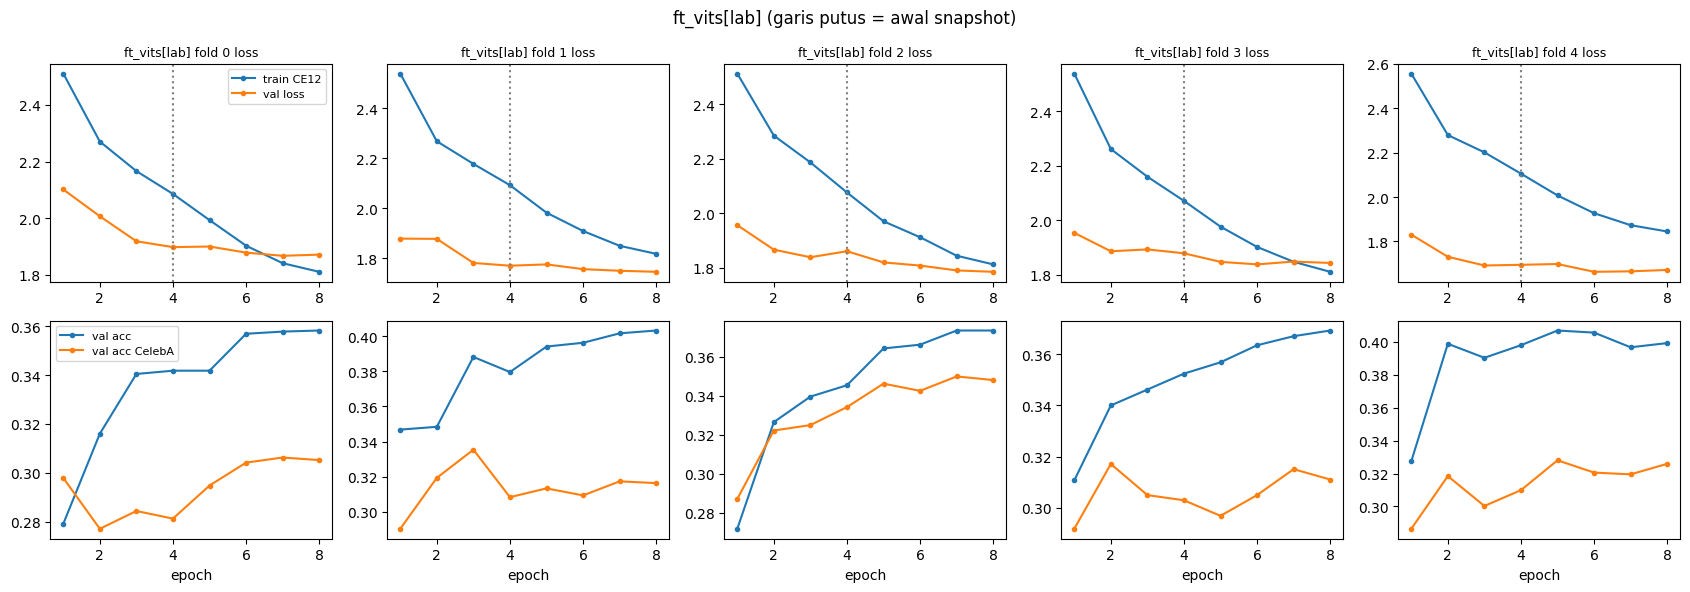

--- ft_vits[lab]: rata-rata semua fold dan seed ---


,train_loss,train_ce12,val_loss,val_acc,val_acc_celeba
epoch,,,,,
1,3.6407,2.5315,1.9442,0.3072,0.2907
2,3.2175,2.2728,1.8735,0.3459,0.3108
3,3.0776,2.1783,1.8245,0.3609,0.3100
4,2.9545,2.0861,1.8204,0.3634,0.3073
5,2.8282,1.9859,1.8081,0.3728,0.3158
6,2.7345,1.9106,1.7888,0.3777,0.3163
7,2.6625,1.8511,1.7842,0.3793,0.3216
8,2.6235,1.8192,1.7834,0.3807,0.3213


ft_vits[lab]: val_loss terendah di epoch 8 dari 8.


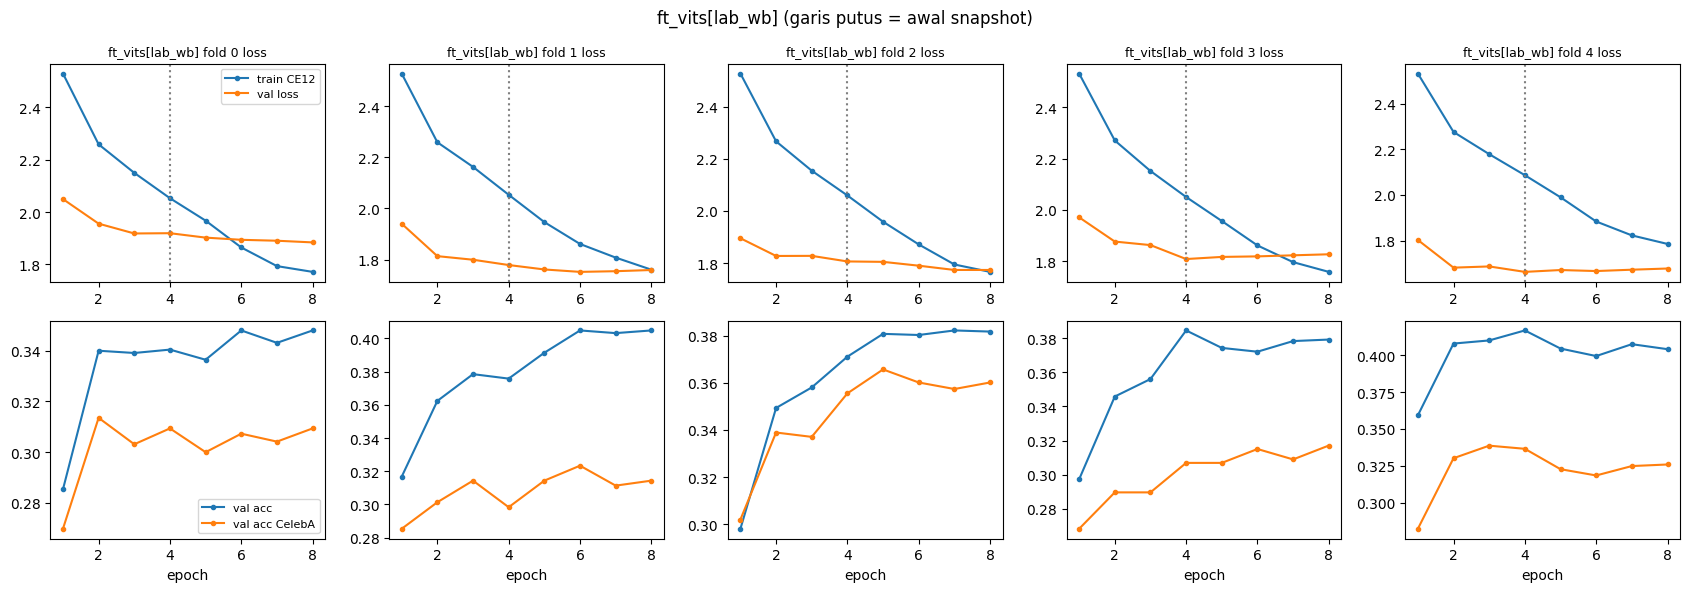

--- ft_vits[lab_wb]: rata-rata semua fold dan seed ---


,train_loss,train_ce12,val_loss,val_acc,val_acc_celeba
epoch,,,,,
1,3.6320,2.5298,1.9317,0.3113,0.2815
2,3.2027,2.2663,1.8308,0.3611,0.3147
3,3.0468,2.1595,1.8189,0.3683,0.3166
4,2.9135,2.0606,1.7950,0.3777,0.3213
5,2.7911,1.9638,1.7911,0.3775,0.3219
6,2.6747,1.8684,1.7841,0.3809,0.3248
7,2.5921,1.8029,1.7827,0.3829,0.3213
8,2.5491,1.7683,1.7842,0.3836,0.3254


ft_vits[lab_wb]: val_loss terendah di epoch 7 dari 8.
OOF subset CelebA (semua komponen):


,acc,macro_f1,top2,top3,worst3_recall,nll,ece
emb_lr,0.2767,0.2519,0.4888,0.6211,0.1222,1.9670,0.0508
color_hgb[lab],0.2991,0.2857,0.4943,0.6218,0.1714,2.0381,0.1284
color_hgb[lab_wb],0.3057,0.2892,0.5088,0.6332,0.1807,2.0466,0.1502
emb_color_lr[lab],0.3015,0.2802,0.5082,0.6514,0.1649,1.9215,0.0461
emb_color_lr[lab_wb],0.3106,0.2902,0.5142,0.6568,0.1712,1.9043,0.0485
ft_vits[lab],0.3281,0.3121,0.5523,0.6810,0.2012,1.9391,0.1207
ft_vits[lab_wb],0.3402,0.3208,0.5559,0.6906,0.2009,1.9396,0.1191


In [22]:
# ============================================================
# 7.3 KURVA LOSS DAN AKURASI (rata-rata seed, per set fitur dan fold)
# ============================================================
H = pd.DataFrame(FT_HIST)
H.to_csv(RESULT_DIR / "E15_ft_history.csv", index=False)
for comp in H["comp"].unique():
    Hc = H[H["comp"] == comp].groupby(["fold", "epoch"])[["train_ce12", "val_loss", "val_acc", "val_acc_celeba"]].mean().reset_index()
    fl = sorted(Hc["fold"].unique())
    fig, axes = plt.subplots(2, len(fl), figsize=(3.4 * len(fl), 6.0), squeeze=False)
    for j, f in enumerate(fl):
        h = Hc[Hc["fold"] == f]
        axes[0, j].plot(h["epoch"], h["train_ce12"], "o-", ms=3, label="train CE12")
        axes[0, j].plot(h["epoch"], h["val_loss"], "o-", ms=3, label="val loss")
        axes[0, j].axvline(FT_SNAPSHOT_FROM, ls=":", color="gray")
        axes[0, j].set_title(f"{comp} fold {f} loss", fontsize=9)
        axes[1, j].plot(h["epoch"], h["val_acc"], "o-", ms=3, label="val acc")
        axes[1, j].plot(h["epoch"], h["val_acc_celeba"], "o-", ms=3, label="val acc CelebA")
        axes[1, j].set_xlabel("epoch")
    axes[0, 0].legend(fontsize=8); axes[1, 0].legend(fontsize=8)
    plt.suptitle(f"{comp} (garis putus = awal snapshot)")
    plt.tight_layout(); plt.savefig(RESULT_DIR / f"E15_ft_curves_{comp.replace('[', '_').replace(']', '')}.png", dpi=110); plt.show()
    mean_h = H[H["comp"] == comp].groupby("epoch")[["train_loss", "train_ce12", "val_loss", "val_acc", "val_acc_celeba"]].mean()
    print(f"--- {comp}: rata-rata semua fold dan seed ---")
    display(mean_h.round(4))
    print(f"{comp}: val_loss terendah di epoch {int(mean_h['val_loss'].idxmin())} dari {FT_EPOCHS}.")

print("OOF subset CelebA (semua komponen):")
display(comp_table(COMP_OOF, y12, cel).round(4))

## 8. Dua ensemble: `lab` (setara E14, ViT-S) vs `lab_wb` (usulan E15)

Untuk tiap set fitur, ensemble log-linear dibangun dari `emb_lr` + `color_hgb[fs]` + `emb_color_lr[fs]` + `ft_vits[fs]`. Bobot dan temperature dipilih dari NLL OOF subset CelebA. Prosedur kedua ensemble identik.

In [23]:
# ============================================================
# 8.1 ENSEMBLE PER SET FITUR
# ============================================================
COMP_T = {n: fit_temperature(y12[cel], COMP_OOF[n][cel]) for n in COMP_OOF}
print("Temperature per komponen:", {n: round(t, 3) for n, t in COMP_T.items()})

def build_ensemble(names):
    oofs = [apply_temperature(COMP_OOF[n], COMP_T[n]) for n in names]
    steps = int(round(1 / ENS_STEP))
    best = None
    for c in itertools.product(range(steps + 1), repeat=len(names)):
        if sum(c) != steps:
            continue
        w = tuple(np.array(c) / steps)
        nll = nll_of(pool([o[cel] for o in oofs], w), y12[cel])
        if best is None or nll < best[0]:
            best = (nll, w)
    w = best[1]
    raw = pool(oofs, w)
    T = fit_temperature(y12[cel], raw[cel])
    return {"names": names, "weights": w, "T": T}

def ens_predict(cfg, comp):
    raw = pool([apply_temperature(comp[n], COMP_T[n]) for n in cfg["names"]], cfg["weights"])
    return apply_temperature(raw, cfg["T"])

ENS = {}
for fs in FEATURE_SETS:
    ENS[fs] = build_ensemble(["emb_lr", f"color_hgb[{fs}]", f"emb_color_lr[{fs}]", f"ft_vits[{fs}]"])
    print(f"ensemble[{fs}] bobot:", dict(zip(ENS[fs]["names"], ENS[fs]["weights"])), f"| T = {ENS[fs]['T']:.3f}")

P_OOF = {f"ensemble[{fs}]": ens_predict(ENS[fs], COMP_OOF) for fs in FEATURE_SETS}
P_TEST = {f"ensemble[{fs}]": ens_predict(ENS[fs], COMP_TEST) for fs in FEATURE_SETS}
P_HOLD = {f"ensemble[{fs}]": ens_predict(ENS[fs], COMP_HOLD) for fs in FEATURE_SETS}
oof_table = comp_table({**COMP_OOF, **P_OOF}, y12, cel)
display(oof_table.round(4))
oof_table.to_csv(RESULT_DIR / "E15_oof_celeba.csv")
print("Angka di atas = OOF subset CelebA.")

Temperature per komponen: {'emb_lr': 1.077, 'color_hgb[lab]': 1.417, 'color_hgb[lab_wb]': 1.498, 'emb_color_lr[lab]': 1.077, 'emb_color_lr[lab_wb]': 1.104, 'ft_vits[lab]': 1.439, 'ft_vits[lab_wb]': 1.447}
ensemble[lab] bobot: {'emb_lr': np.float64(0.0), 'color_hgb[lab]': np.float64(0.2), 'emb_color_lr[lab]': np.float64(0.3), 'ft_vits[lab]': np.float64(0.5)} | T = 0.890
ensemble[lab_wb] bobot: {'emb_lr': np.float64(0.1), 'color_hgb[lab_wb]': np.float64(0.2), 'emb_color_lr[lab_wb]': np.float64(0.2), 'ft_vits[lab_wb]': np.float64(0.5)} | T = 0.887


,acc,macro_f1,top2,top3,worst3_recall,nll,ece
emb_lr,0.2767,0.2519,0.4888,0.6211,0.1222,1.9670,0.0508
color_hgb[lab],0.2991,0.2857,0.4943,0.6218,0.1714,2.0381,0.1284
color_hgb[lab_wb],0.3057,0.2892,0.5088,0.6332,0.1807,2.0466,0.1502
emb_color_lr[lab],0.3015,0.2802,0.5082,0.6514,0.1649,1.9215,0.0461
emb_color_lr[lab_wb],0.3106,0.2902,0.5142,0.6568,0.1712,1.9043,0.0485
ft_vits[lab],0.3281,0.3121,0.5523,0.6810,0.2012,1.9391,0.1207
ft_vits[lab_wb],0.3402,0.3208,0.5559,0.6906,0.2009,1.9396,0.1191
ensemble[lab],0.3360,0.3171,0.5601,0.6961,0.1937,1.8491,0.0254
ensemble[lab_wb],0.3390,0.3196,0.5686,0.6997,0.2018,1.8409,0.0291


Angka di atas = OOF subset CelebA.


## 9. Official test (acuan utama) dan holdout — label dipakai mulai di sini

In [24]:
# ============================================================
# 9.1 OFFICIAL TEST + HOLDOUT, CI BOOTSTRAP, DAN UJI BERPASANGAN lab_wb vs lab
# ============================================================
def bootstrap_ci(y, p, seed=SEED):
    rng = np.random.default_rng(seed)
    pred, m = p.argmax(1), full_metrics(y, p)
    ok, top3 = pred == y, (np.argsort(-p, axis=1)[:, :3] == y[:, None]).any(1)
    boot = {"acc": [], "macro_f1": [], "top3": []}
    for _ in range(N_BOOT):
        ix = rng.integers(0, len(y), len(y))
        boot["acc"].append(ok[ix].mean())
        boot["macro_f1"].append(sk_f1_score(y[ix], pred[ix], average="macro", labels=list(range(NUM_CLASSES)), zero_division=0))
        boot["top3"].append(top3[ix].mean())
    return pd.DataFrame({k: {"nilai": m[k], "ci95_lo": np.percentile(v, 2.5), "ci95_hi": np.percentile(v, 97.5)} for k, v in boot.items()}).T

def paired_diff(y, pa, pb, seed=SEED):
    rng = np.random.default_rng(seed)
    a, b = pa.argmax(1) == y, pb.argmax(1) == y
    d = [a[ix].mean() - b[ix].mean() for ix in (rng.integers(0, len(y), len(y)) for _ in range(N_BOOT))]
    return float(a.mean() - b.mean()), float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))

FINAL_NAME = f"ensemble[{FINAL_FEATURE_SET}]"
BASE_NAME = "ensemble[lab]"

test_table = comp_table({**COMP_TEST, **P_TEST}, yte)
print(f"=== OFFICIAL TEST ({len(test_rows)} gambar) — ACUAN UTAMA ===")
display(pd.concat([test_table, pd.DataFrame(REFERENCE).T]).round(4))
test_table.to_csv(RESULT_DIR / "E15_test_metrics.csv")
p_test = P_TEST[FINAL_NAME]
test_m = test_table.loc[FINAL_NAME].to_dict()
ci_te = bootstrap_ci(yte, p_test)
display(ci_te.round(4))

hold_table = comp_table({**COMP_HOLD, **P_HOLD}, yho)
print(f"\n=== HOLDOUT ({len(hold_rows)} gambar CelebA) — pemeriksaan kedua ===")
display(hold_table.round(4))
hold_table.to_csv(RESULT_DIR / "E15_holdout_metrics.csv")
p_hold = P_HOLD[FINAL_NAME]
hold_m = hold_table.loc[FINAL_NAME].to_dict()

rows = []
for split, y_, P_ in (("official test", yte, P_TEST), ("holdout", yho, P_HOLD)):
    d, lo, hi = paired_diff(y_, P_[FINAL_NAME], P_[BASE_NAME])
    rows.append({"data": split, "acc_lab_wb": (P_[FINAL_NAME].argmax(1) == y_).mean(), "acc_lab": (P_[BASE_NAME].argmax(1) == y_).mean(),
                 "selisih": d, "ci95_lo": lo, "ci95_hi": hi,
                 "kesimpulan": "lab_wb LEBIH BAIK" if lo > 0 else "lab_wb LEBIH BURUK" if hi < 0 else "tidak berbeda nyata"})
for comp_base in ["color_hgb", "emb_color_lr", "ft_vits"]:
    d, lo, hi = paired_diff(yte, COMP_TEST[f"{comp_base}[lab_wb]"], COMP_TEST[f"{comp_base}[lab]"])
    rows.append({"data": f"official test — {comp_base}", "acc_lab_wb": (COMP_TEST[f"{comp_base}[lab_wb]"].argmax(1) == yte).mean(),
                 "acc_lab": (COMP_TEST[f"{comp_base}[lab]"].argmax(1) == yte).mean(), "selisih": d, "ci95_lo": lo, "ci95_hi": hi,
                 "kesimpulan": "lab_wb LEBIH BAIK" if lo > 0 else "lab_wb LEBIH BURUK" if hi < 0 else "tidak berbeda nyata"})
ablation_df = pd.DataFrame(rows)
print("\n=== ABLASI: fitur tahan white balance (lab_wb) dikurangi fitur Lab E14 (lab), bootstrap berpasangan ===")
display(ablation_df.round(4))
ablation_df.to_csv(RESULT_DIR / "E15_ablation.csv", index=False)

lo, hi = ci_te.loc["acc", "ci95_lo"], ci_te.loc["acc", "ci95_hi"]
print(f"\nAkurasi sub-season OFFICIAL TEST = {test_m['acc']:.4f} (CI95 {lo:.4f}–{hi:.4f}) | target {TARGET_ACC:.0%}: "
      + ("TERCAPAI" if lo >= TARGET_ACC else "belum pasti (target di dalam CI)" if hi >= TARGET_ACC else "BELUM tercapai"))
for ref in ["E12 ensemble test", "E14 ensemble test"]:
    print(f"Dibanding {ref} ({REFERENCE[ref]['acc']:.4f}): selisih {test_m['acc'] - REFERENCE[ref]['acc']:+.4f}")

=== OFFICIAL TEST (912 gambar) — ACUAN UTAMA ===


,acc,macro_f1,top2,top3,worst3_recall,nll,ece
emb_lr,0.2982,0.2606,0.5197,0.6491,0.0676,1.8993,0.0562
color_hgb[lab],0.3048,0.2821,0.5208,0.6436,0.1534,2.0125,0.1389
color_hgb[lab_wb],0.3169,0.2916,0.5285,0.6645,0.1776,1.9635,0.1349
emb_color_lr[lab],0.3180,0.2863,0.5373,0.6732,0.1120,1.8594,0.0397
emb_color_lr[lab_wb],0.3257,0.3002,0.5592,0.6908,0.1224,1.8444,0.0576
ft_vits[lab],0.3322,0.3100,0.5757,0.6831,0.1675,1.8691,0.1023
ft_vits[lab_wb],0.3311,0.3072,0.5603,0.6798,0.1726,1.8659,0.1049
ensemble[lab],0.3443,0.3206,0.5811,0.6974,0.1659,1.8058,0.0458
ensemble[lab_wb],0.3520,0.3282,0.5691,0.6974,0.1755,1.7969,0.0469
EfficientNet-B0 test,0.2895,0.2604,NaN,NaN,NaN,NaN,NaN


,nilai,ci95_lo,ci95_hi
acc,0.3520,0.3213,0.3827
macro_f1,0.3282,0.2961,0.3574
top3,0.6974,0.6689,0.7259



=== HOLDOUT (414 gambar CelebA) — pemeriksaan kedua ===


,acc,macro_f1,top2,top3,worst3_recall,nll,ece
emb_lr,0.2826,0.2597,0.4879,0.6135,0.1132,1.9754,0.0809
color_hgb[lab],0.2754,0.2699,0.5000,0.6039,0.1564,2.0823,0.1765
color_hgb[lab_wb],0.2923,0.2751,0.5338,0.6667,0.1473,1.9843,0.1425
emb_color_lr[lab],0.3188,0.2995,0.5266,0.6643,0.1441,1.9223,0.0641
emb_color_lr[lab_wb],0.3213,0.3034,0.5435,0.6643,0.1600,1.8963,0.0968
ft_vits[lab],0.3237,0.3029,0.5725,0.6981,0.1368,1.9038,0.1072
ft_vits[lab_wb],0.2971,0.2727,0.5990,0.6932,0.1249,1.9070,0.1464
ensemble[lab],0.3213,0.3015,0.5870,0.6860,0.1475,1.8479,0.0450
ensemble[lab_wb],0.3213,0.3041,0.6014,0.7029,0.1705,1.8320,0.0499



=== ABLASI: fitur tahan white balance (lab_wb) dikurangi fitur Lab E14 (lab), bootstrap berpasangan ===


,data,acc_lab_wb,acc_lab,selisih,ci95_lo,ci95_hi,kesimpulan
0,official test,0.3520,0.3443,0.0077,-0.0077,0.0241,tidak berbeda nyata
1,holdout,0.3213,0.3213,0.0000,-0.0242,0.0242,tidak berbeda nyata
2,official test — color_hgb,0.3169,0.3048,0.0121,-0.0154,0.0373,tidak berbeda nyata
3,official test — emb_color_lr,0.3257,0.3180,0.0077,-0.0055,0.0208,tidak berbeda nyata
4,official test — ft_vits,0.3311,0.3322,-0.0011,-0.0175,0.0154,tidak berbeda nyata



Akurasi sub-season OFFICIAL TEST = 0.3520 (CI95 0.3213–0.3827) | target 50%: BELUM tercapai
Dibanding E12 ensemble test (0.3542): selisih -0.0022
Dibanding E14 ensemble test (0.3465): selisih +0.0055


,class,support,precision,recall_lab_wb,recall_lab,f1,selisih_recall
0,estate_soft,63,0.151,0.127,0.127,0.138,0.000
1,primavera_bright,66,0.250,0.167,0.152,0.200,0.015
2,autunno_soft,73,0.221,0.233,0.219,0.227,0.014
3,estate_cool,53,0.250,0.283,0.226,0.265,0.057
4,inverno_bright,58,0.383,0.310,0.328,0.343,-0.017
5,estate_light,70,0.489,0.314,0.300,0.383,0.014
6,autunno_warm,74,0.462,0.324,0.311,0.381,0.014
7,primavera_warm,73,0.375,0.329,0.356,0.350,-0.027
8,inverno_cool,89,0.341,0.348,0.371,0.344,-0.022
9,primavera_light,64,0.300,0.422,0.406,0.351,0.016


Jumlah kesalahan dua arah pada pasangan yang sering tertukar (negatif = berkurang):


,pasangan,salah_lab,salah_lab_wb,selisih
0,autunno_deep <-> inverno_deep,70,68,-2
1,estate_light <-> primavera_light,31,32,1
2,inverno_cool <-> inverno_deep,46,42,-4
3,autunno_warm <-> primavera_warm,18,16,-2
4,estate_soft <-> autunno_soft,17,17,0
5,primavera_bright <-> inverno_bright,12,11,-1


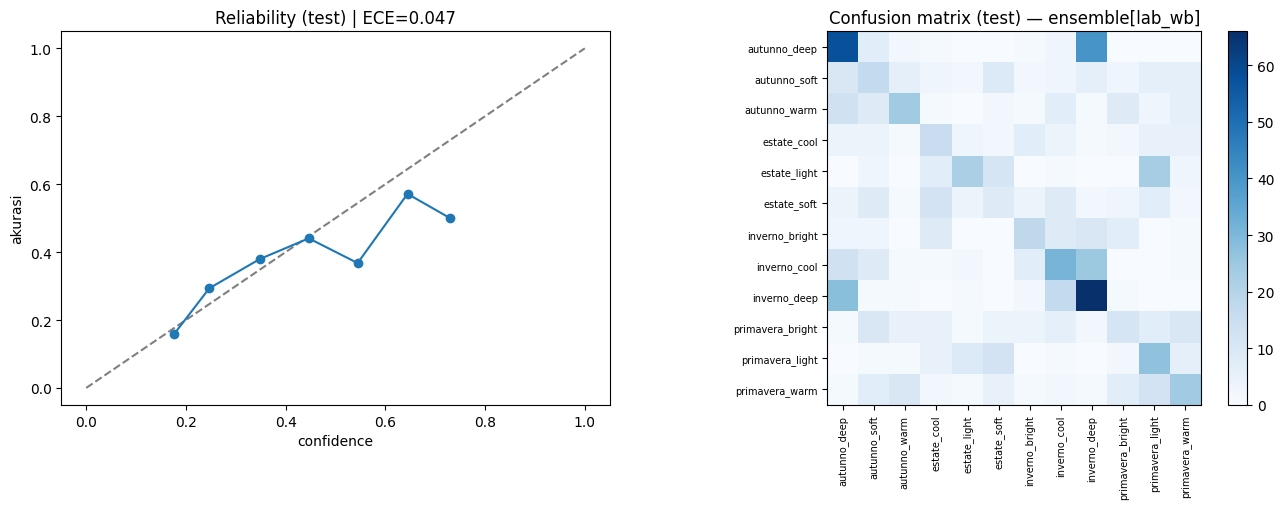

In [25]:
# ============================================================
# 9.2 PER SUB-SEASON DAN PASANGAN YANG SERING TERTUKAR (official test)
# ============================================================
pred_e, conf_te = p_test.argmax(1), p_test.max(1)
pred_b = P_TEST[BASE_NAME].argmax(1)
prec, rec, f1c, sup = precision_recall_fscore_support(yte, pred_e, labels=list(range(NUM_CLASSES)), zero_division=0)
_, rec_b, _, _ = precision_recall_fscore_support(yte, pred_b, labels=list(range(NUM_CLASSES)), zero_division=0)
per_class_df = pd.DataFrame({"class": class_names, "support": sup, "precision": prec, "recall_lab_wb": rec,
                             "recall_lab": rec_b, "f1": f1c})
per_class_df["selisih_recall"] = per_class_df["recall_lab_wb"] - per_class_df["recall_lab"]
display(per_class_df.sort_values("recall_lab_wb").round(3).reset_index(drop=True))
per_class_df.to_csv(RESULT_DIR / "E15_per_subseason.csv", index=False)

cm_new = confusion_matrix(yte, pred_e, labels=list(range(NUM_CLASSES)))
cm_old = confusion_matrix(yte, pred_b, labels=list(range(NUM_CLASSES)))
rows = []
for a, b in FOCUS_PAIRS:
    ia, ib = class2idx[a], class2idx[b]
    rows.append({"pasangan": f"{a} <-> {b}", "salah_lab": int(cm_old[ia, ib] + cm_old[ib, ia]),
                 "salah_lab_wb": int(cm_new[ia, ib] + cm_new[ib, ia])})
focus_df = pd.DataFrame(rows)
focus_df["selisih"] = focus_df["salah_lab_wb"] - focus_df["salah_lab"]
print("Jumlah kesalahan dua arah pada pasangan yang sering tertukar (negatif = berkurang):")
display(focus_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
edges = np.linspace(0, 1, 11)
xs, ys = [], []
for i in range(10):
    m = (conf_te >= edges[i]) & (conf_te < edges[i + 1] if i < 9 else conf_te <= edges[i + 1])
    if m.sum() >= 5:
        xs.append(conf_te[m].mean()); ys.append((pred_e == yte)[m].mean())
axes[0].plot([0, 1], [0, 1], "--", color="gray"); axes[0].plot(xs, ys, "o-")
axes[0].set_xlabel("confidence"); axes[0].set_ylabel("akurasi"); axes[0].set_title(f"Reliability (test) | ECE={test_m['ece']:.3f}")
im = axes[1].imshow(cm_new, cmap="Blues")
axes[1].set_xticks(range(NUM_CLASSES)); axes[1].set_yticks(range(NUM_CLASSES))
axes[1].set_xticklabels(class_names, rotation=90, fontsize=7); axes[1].set_yticklabels(class_names, fontsize=7)
axes[1].set_title(f"Confusion matrix (test) — {FINAL_NAME}"); plt.colorbar(im, ax=axes[1], fraction=0.046)
plt.tight_layout(); plt.savefig(RESULT_DIR / "E15_test_diagnostics.png", dpi=130); plt.show()

In [26]:
# ============================================================
# 10. SIMPAN ARTEFAK
# ============================================================
artifacts = {
    "experiment_id": EXPERIMENT_ID, "class_names": class_names, "season_of": season_of, "char_of": char_of, "warm_of": warm_of,
    "feature_sets": FEATURE_SETS, "final_feature_set": FINAL_FEATURE_SET, "region_cols": REGION_COLS, "wb_cols": WB_COLS,
    "ensembles": {fs: {k: v for k, v in cfg.items()} for fs, cfg in ENS.items()}, "comp_temps": COMP_T,
    "models": COMP_MODEL, "emb_keys": EMB_KEYS, "C_emb_lr": BEST_C, "C_emb_color_lr": BEST_C_EC,
    "color_preps": COLOR_PREPS, "frozen_backbone": FROZEN_HF_ID, "ft_backbone": FT_HF_ID, "parser": PARSER_HF_ID,
    "parse_size": PARSE_SIZE, "cache_size": CACHE_SIZE, "ft_img_size": FT_IMG_SIZE, "mask_used": bool(MASK_OK),
    "ft_ckpts": [f"ft_vits_{fs}_s{s}f{k}.pt" for fs in FEATURE_SETS for s in FT_SEEDS for k in range(N_FOLDS)],
    "ft_freeze_blocks": FT_FREEZE_BLOCKS, "ft_snapshot_from": FT_SNAPSHOT_FROM, "ft_epochs": FT_EPOCHS,
}
dump(artifacts, RESULT_DIR / "E15_artifacts.joblib")
pd.DataFrame({
    "path": df["resolved_path"].astype(str).to_numpy()[test_rows],
    "true": [idx2class[i] for i in yte], "pred": [idx2class[i] for i in pred_e], "pred_lab": [idx2class[i] for i in pred_b],
    "confidence": conf_te, "top3": ["|".join(class_names[j] for j in np.argsort(-p_test[i])[:3]) for i in range(len(test_rows))],
}).to_csv(RESULT_DIR / "E15_test_predictions.csv", index=False)
summary = {"experiment_id": EXPERIMENT_ID, "smoke_test": SMOKE_TEST, "final": FINAL_NAME,
           "ensembles": {fs: {"weights": dict(zip(c["names"], c["weights"])), "T": c["T"]} for fs, c in ENS.items()},
           "test_metrics": test_m, "holdout_metrics": hold_m,
           "ablation": ablation_df.to_dict(orient="records"), "focus_pairs": focus_df.to_dict(orient="records"),
           "pair_auroc": diag_df.to_dict(orient="records"), "target_acc": TARGET_ACC}
(RESULT_DIR / "E15_summary.json").write_text(json.dumps(summary, indent=2, default=float))
print("Tersimpan di", RESULT_DIR)

Tersimpan di /kaggle/working/E15


In [27]:
# ============================================================
# 11. CATAT HASIL KE modellab_registry (notebook + catatan hasil -> repo GitHub)
# ============================================================
import modellab_registry

# 0. Kumpulkan metrik official test (ensemble E15 dengan fitur tahan white balance) + holdout + ablasi
_prec, _rec, _, _ = precision_recall_fscore_support(yte, pred_e, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0)
_abl = ablation_df.iloc[0]
final_metrics = {"accuracy": test_m["acc"], "macro_f1": test_m["macro_f1"], "macro_precision": float(_prec),
                 "macro_recall": float(_rec), "top3": test_m["top3"],
                 "accuracy_tanpa_fitur_wb": float(_abl["acc_lab"]), "selisih_vs_tanpa_wb": float(_abl["selisih"]),
                 "holdout_accuracy": hold_m["acc"]}
print({k: round(float(v), 4) for k, v in final_metrics.items()})

# 1. Ekstrak hasil evaluasi yang sudah dihitung oleh notebook di sel sebelumnya
accuracy = final_metrics["accuracy"]
f1_score = final_metrics["macro_f1"]
precision = final_metrics["macro_precision"]
recall = final_metrics["macro_recall"]

# 2. Panggil fungsi auto-log, sertakan globals() dan panggil variabel konfigurasi master
modellab_registry.auto_log_experiment(
    env_globals=globals(),
    topic="topic-a",
    model="DINOv3 ViT-S/16 Fusion + fitur tahan white balance",
    objective=("E15: fitur warna tahan white balance & efek kamera (log-rasio RGB linear antar region, kromatisitas, "
               "HSV, YCrCb, cast gray-world; diadaptasi dari notebook undertone EXP-7e87) + ablasi vs fitur Lab E14"),
    dataset="deep_armocromia",
    owner="Fatih Itsbatul Haq"
)

{'accuracy': 0.352, 'macro_f1': 0.3282, 'macro_precision': 0.3399, 'macro_recall': 0.3283, 'top3': 0.6974, 'accuracy_tanpa_fitur_wb': 0.3443, 'selisih_vs_tanpa_wb': 0.0077, 'holdout_accuracy': 0.3213}
===REGISTRY_PAYLOAD_START===
{"topic": "topic-a", "model": "DINOv3 ViT-S/16 Fusion + fitur tahan white balance", "objective": "E15: fitur warna tahan white balance & efek kamera (log-rasio RGB linear antar region, kromatisitas, HSV, YCrCb, cast gray-world; diadaptasi dari notebook undertone EXP-7e87) + ablasi vs fitur Lab E14", "dataset": "deep_armocromia", "owner": "Fatih Itsbatul Haq", "metrics": {"accuracy": 0.3519736842105263, "f1": 0.32822349193761313, "precision": 0.3399157574748033, "recall": 0.3282848064241071}}
===REGISTRY_PAYLOAD_END===
